**Linear LogReg probe PCA on English 5000 data ONLY ON MBERT, new surprise and fear w/o emojis and clean code and BRIGHTER+XED English + German test set + mDeBERTa, with BALANCED calibration AND (printed) PROBE WEIGHTS! ALSO ADDED EVALUATION TO PROJECTION METHODS (+ probe). Additional German calibration and a 6D classifier + probe training on hand labeled data. Estonian is smaller. CORRECT ONE!!**

In [1]:
import pandas as pd
import numpy as np
import torch
from transformers import AutoTokenizer, AutoModel
from tqdm import tqdm
from sklearn.decomposition import PCA
from sklearn.preprocessing import normalize
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, balanced_accuracy_score, f1_score
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
DATA_FILE = "combined_english_cleaned_surprise_and_fear_balanced.csv"
MAX_LENGTH = 128
BATCH_SIZE = 32
RANDOM_STATE = 42

In [3]:
# Pooling

def mean_pooling(model_output, attention_mask):
    token_embeddings = model_output.last_hidden_state
    input_mask_expanded = attention_mask.unsqueeze(-1).expand(token_embeddings.size()).float()

    summed = torch.sum(token_embeddings * input_mask_expanded, dim=1)
    counts = torch.clamp(input_mask_expanded.sum(dim=1), min=1e-9)
    return summed / counts

def cls_pooling(model_output):
    return model_output.last_hidden_state[:, 0, :]

In [4]:
# Encoding
def encode_texts(text_list, tokenizer, model, device, batch_size=32, max_length=128):
    mean_embs = []
    cls_embs = []

    with torch.no_grad():
        for i in tqdm(range(0, len(text_list), batch_size), desc="Encoding"):
            batch_texts = text_list[i:i + batch_size]

            encoded = tokenizer(
                batch_texts,
                padding=True,
                truncation=True,
                max_length=max_length,
                return_tensors="pt"
            )
            encoded = {k: v.to(device) for k, v in encoded.items()}

            outputs = model(**encoded)

            mean_emb = mean_pooling(outputs, encoded["attention_mask"])
            cls_emb = cls_pooling(outputs)

            mean_embs.append(mean_emb.cpu().numpy())
            cls_embs.append(cls_emb.cpu().numpy())

    return np.vstack(mean_embs), np.vstack(cls_embs)

In [5]:
# Centroids

def compute_centroids(embeddings, df, emotion_order):
    centroids = []
    for emotion in emotion_order:
        mask = (df["emotion"] == emotion).values
        centroids.append(embeddings[mask].mean(axis=0))
    centroids = np.vstack(centroids)
    return normalize(centroids, norm="l2")

In [6]:
# PCA

def plot_centroids_in_full_pca_2d(embeddings, centroids, emotion_order, title):
    pca = PCA(n_components=2, random_state=RANDOM_STATE)
    pca.fit(embeddings)
    centroids_2d = pca.transform(centroids)

    print(f"\n{title}")
    print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))

    plt.figure(figsize=(8, 6))
    for i, emotion in enumerate(emotion_order):
        plt.scatter(centroids_2d[i, 0], centroids_2d[i, 1], s=160)
        plt.text(
            centroids_2d[i, 0],
            centroids_2d[i, 1],
            emotion,
            fontsize=11,
            ha='center',
            va='center'
        )

    plt.title(title)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.grid(alpha=0.25)
    plt.show()

def plot_centroids_in_full_pca_3d(embeddings, centroids, emotion_order, title):
    pca = PCA(n_components=3, random_state=RANDOM_STATE)
    pca.fit(embeddings)
    centroids_3d = pca.transform(centroids)

    print(f"\n{title}")
    print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))

    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection="3d")

    for i, emotion in enumerate(emotion_order):
        ax.scatter(
            centroids_3d[i, 0],
            centroids_3d[i, 1],
            centroids_3d[i, 2],
            s=140
        )
        ax.text(
            centroids_3d[i, 0],
            centroids_3d[i, 1],
            centroids_3d[i, 2],
            emotion,
            fontsize=11
        )

    ax.set_title(title)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_zlabel("PC3")
    plt.show()

In [7]:
# Probe training
def train_probe(embeddings, labels, name):
    X_train, X_test, y_train, y_test = train_test_split(
        embeddings,
        labels,
        test_size=0.2,
        random_state=RANDOM_STATE,
        stratify=labels
    )

    clf = LogisticRegression(
        max_iter=3000,
        solver="lbfgs",
        random_state=RANDOM_STATE,
        class_weight="balanced"
    )
    clf.fit(X_train, y_train)

    y_pred = clf.predict(X_test)

    print(f"\n=== {name} probe ===")
    print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(y_test, y_pred), 4))
    print("Macro F1:", round(f1_score(y_test, y_pred, average="macro"), 4))
    print("Weighted F1:", round(f1_score(y_test, y_pred, average="weighted"), 4))
    print(classification_report(y_test, y_pred, digits=3))

    return clf

In [8]:
# Linear probe PCA
def get_probe_space(probe, embeddings, use_probabilities=False):
    if use_probabilities:
        return probe.predict_proba(embeddings)
    else:
        scores = probe.decision_function(embeddings)

        if scores.ndim == 1:
            scores = scores[:, None]

        return scores


def plot_probe_pca_2d(probe, embeddings, labels, emotion_order, title, use_probabilities=False):
    probe_space = get_probe_space(probe, embeddings, use_probabilities=use_probabilities)

    pca = PCA(n_components=2, random_state=RANDOM_STATE)
    X_2d = pca.fit_transform(probe_space)

    print(f"\n{title}")
    print("Probe space shape:", probe_space.shape)
    print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))

    plt.figure(figsize=(9, 7))
    for emotion in emotion_order:
        mask = (np.array(labels) == emotion)
        plt.scatter(
            X_2d[mask, 0],
            X_2d[mask, 1],
            label=emotion,
            alpha=0.35,
            s=10
        )

    plt.title(title)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.legend()
    plt.grid(alpha=0.2)
    plt.show()


def plot_probe_centroids_pca_2d(probe, embeddings, df, emotion_order, title, use_probabilities=False):
    probe_space = get_probe_space(probe, embeddings, use_probabilities=use_probabilities)

    # centroid in probe space
    centroids = []
    for emotion in emotion_order:
        mask = (df["emotion"] == emotion).values
        centroids.append(probe_space[mask].mean(axis=0))
    centroids = np.vstack(centroids)

    pca = PCA(n_components=2, random_state=RANDOM_STATE)
    pca.fit(probe_space)
    centroids_2d = pca.transform(centroids)

    print(f"\n{title}")
    print("Probe space shape:", probe_space.shape)
    print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))

    dx = (centroids_2d[:, 0].max() - centroids_2d[:, 0].min()) * 0.02
    dy = (centroids_2d[:, 1].max() - centroids_2d[:, 1].min()) * 0.02

    plt.figure(figsize=(8, 6))
    for i, emotion in enumerate(emotion_order):
        plt.scatter(centroids_2d[i, 0], centroids_2d[i, 1], s=180)
        plt.text(
            centroids_2d[i, 0] + dx,
            centroids_2d[i, 1] + dy,
            emotion,
            fontsize=11
        )

    plt.title(title)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.grid(alpha=0.25)
    plt.show()


def plot_probe_kde_pca_2d(probe, embeddings, labels, emotion_order, title, use_probabilities=True):
    probe_space = get_probe_space(probe, embeddings, use_probabilities=use_probabilities)

    pca = PCA(n_components=2, random_state=RANDOM_STATE)
    X_2d = pca.fit_transform(probe_space)

    print(f"\n{title}")
    print("Probe space shape:", probe_space.shape)
    print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))

    plt.figure(figsize=(9, 7))

    # scatter lightly underneath
    for emotion in emotion_order:
        mask = (np.array(labels) == emotion)
        plt.scatter(
            X_2d[mask, 0],
            X_2d[mask, 1],
            alpha=0.08,
            s=8,
            label=emotion
        )

    # KDE contours if seaborn is available
    try:
        import seaborn as sns

        for emotion in emotion_order:
            mask = (np.array(labels) == emotion)
            sns.kdeplot(
                x=X_2d[mask, 0],
                y=X_2d[mask, 1],
                levels=[0.25, 0.5],
                linewidths=2
            )
    except ImportError:
        print("seaborn not installed, showing scatter only.")

    plt.title(title)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.legend()
    plt.grid(alpha=0.2)
    plt.show()

In [9]:
# Example prediction
example_texts = [
    "I am so happy and excited about this!",
    "This is disgusting and makes me sick.",
    "I am terrified something bad will happen.",
    "I miss you so much and feel empty.",
    "What a wonderful surprise!",
    "I am furious and cannot stand this anymore."
]

def predict_examples(text_list, tokenizer, model, device, probe, use_mean=True):
    mean_embs, cls_embs = encode_texts(
        text_list, tokenizer, model, device,
        batch_size=8, max_length=MAX_LENGTH
    )

    embs = mean_embs if use_mean else cls_embs
    embs = normalize(embs, norm="l2")

    preds = probe.predict(embs)
    probs = probe.predict_proba(embs)

    for text, pred, prob in zip(text_list, preds, probs):
        top_idx = np.argsort(prob)[::-1][:3]
        top3 = [(probe.classes_[i], round(float(prob[i]), 3)) for i in top_idx]

        print("\nTEXT:", text)
        print("Predicted:", pred)
        print("Top-3:", top3)

In [10]:

# Probe weight analysis

def get_probe_weight_matrix(probe):
    """
    Returns normalized probe weight vectors.
    Shape: (n_classes, hidden_dim)
    """
    if not hasattr(probe, "coef_"):
        raise ValueError("Probe does not expose coef_. This works for LogisticRegression.")
    W = probe.coef_.copy()
    return normalize(W, norm="l2")


def plot_probe_weight_cosine_similarity(probe, class_order, title):
    W = get_probe_weight_matrix(probe)
    sim = cosine_similarity(W)
    sim_df = pd.DataFrame(sim, index=class_order, columns=class_order).round(3)

    print(f"\n{title}")
    print(sim_df)

    plt.figure(figsize=(7, 6))
    plt.imshow(sim, interpolation="nearest")
    plt.xticks(range(len(class_order)), class_order, rotation=45, ha="right")
    plt.yticks(range(len(class_order)), class_order)
    plt.colorbar()
    plt.title(title)
    plt.tight_layout()
    plt.show()

    return sim_df


def plot_probe_weights_pca_2d(probe, class_order, title):
    """
    PCA on probe weight vectors themselves.
    Each point = one emotion direction.
    """
    W = get_probe_weight_matrix(probe)

    # with few classes, max possible rank is limited
    n_comp = min(2, W.shape[0], W.shape[1])
    pca = PCA(n_components=n_comp, random_state=RANDOM_STATE)
    W_2d = pca.fit_transform(W)

    print(f"\n{title}")
    print("Weight matrix shape:", W.shape)
    print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))

    plt.figure(figsize=(8, 6))
    for i, emotion in enumerate(class_order):
        plt.scatter(W_2d[i, 0], W_2d[i, 1], s=180)
        plt.text(W_2d[i, 0], W_2d[i, 1], emotion, fontsize=11)

    plt.title(title)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.grid(alpha=0.25)
    plt.show()

    return W_2d, pca


def plot_probe_weights_pca_3d(probe, class_order, title):
    W = get_probe_weight_matrix(probe)

    n_comp = min(3, W.shape[0], W.shape[1])
    if n_comp < 3:
        print(f"\n{title}")
        print("Not enough dimensions/classes for 3D PCA.")
        return None, None

    pca = PCA(n_components=3, random_state=RANDOM_STATE)
    W_3d = pca.fit_transform(W)

    print(f"\n{title}")
    print("Weight matrix shape:", W.shape)
    print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))

    # 🔽 ADD THIS BLOCK
    print("\n3D PCA coordinates (per emotion):")
    coords_df = pd.DataFrame(W_3d, columns=["PC1", "PC2", "PC3"])
    coords_df["emotion"] = class_order
    print(coords_df.round(4).to_string(index=False))

    # Also print in Desmos-friendly format
    print("\nDesmos-friendly format:")
    for i, emotion in enumerate(class_order):
        x, y, z = W_3d[i]
        print(f"{emotion}: ({x:.4f}, {y:.4f}, {z:.4f})")

    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection="3d")

    for i, emotion in enumerate(class_order):
        ax.scatter(W_3d[i, 0], W_3d[i, 1], W_3d[i, 2], s=160)
        ax.text(W_3d[i, 0], W_3d[i, 1], W_3d[i, 2], emotion, fontsize=10)

    ax.set_title(title)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_zlabel("PC3")
    plt.show()

    return W_3d, pca


def plot_probe_weights_vs_centroids_pca_2d(probe, centroids, class_order, title):
    """
    Compare probe weight vectors and class centroids in the same PCA space.
    PCA is fit on the combined matrix [weights; centroids].
    """
    W = get_probe_weight_matrix(probe)
    C = normalize(centroids.copy(), norm="l2")

    combined = np.vstack([W, C])

    pca = PCA(n_components=2, random_state=RANDOM_STATE)
    combined_2d = pca.fit_transform(combined)

    W_2d = combined_2d[:len(class_order)]
    C_2d = combined_2d[len(class_order):]

    print(f"\n{title}")
    print("Combined shape:", combined.shape)
    print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))

    plt.figure(figsize=(9, 7))

    for i, emotion in enumerate(class_order):
        # weights
        plt.scatter(W_2d[i, 0], W_2d[i, 1], marker="^", s=180)
        plt.text(W_2d[i, 0], W_2d[i, 1], f"{emotion}_W", fontsize=10)

        # centroids
        plt.scatter(C_2d[i, 0], C_2d[i, 1], marker="o", s=180)
        plt.text(C_2d[i, 0], C_2d[i, 1], f"{emotion}_C", fontsize=10)

        # line connecting them
        plt.plot(
            [W_2d[i, 0], C_2d[i, 0]],
            [W_2d[i, 1], C_2d[i, 1]],
            linestyle="--",
            alpha=0.5
        )

    plt.title(title)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.grid(alpha=0.25)
    plt.show()

    return W_2d, C_2d, pca


def plot_probe_weight_projection_histograms(probe, embeddings, labels, emotion_order, title_prefix):
    """
    For each emotion direction, project all embeddings onto that weight vector.
    This shows whether the corresponding class tends to score higher along its own direction.
    """
    W = get_probe_weight_matrix(probe)
    X = normalize(embeddings.copy(), norm="l2")
    label_array = np.array(labels)

    for i, emotion in enumerate(emotion_order):
        scores = X @ W[i]

        plt.figure(figsize=(8, 5))
        for e in emotion_order:
            mask = label_array == e
            plt.hist(scores[mask], bins=40, alpha=0.35, label=e, density=True)

        plt.title(f"{title_prefix}: projection onto '{emotion}' weight")
        plt.xlabel("Cosine-like projection score")
        plt.ylabel("Density")
        plt.legend()
        plt.grid(alpha=0.2)
        plt.show()

In [11]:

# Projection-based classifiers

def get_probe_weight_matrix(probe):
    """
    Returns normalized probe weight vectors.
    Shape: (n_classes, hidden_dim)
    """
    W = probe.coef_.copy()
    return normalize(W, norm="l2")


def predict_with_weight_cosine(embeddings, probe, class_order):
    """
    Classify by cosine similarity between embeddings and probe weight vectors.
    """
    X = normalize(embeddings.copy(), norm="l2")
    W = get_probe_weight_matrix(probe)  # already normalized

    scores = X @ W.T   # cosine-like similarity since both normalized
    pred_idx = np.argmax(scores, axis=1)
    preds = np.array([class_order[i] for i in pred_idx])

    return preds, scores


def predict_with_prototypes(embeddings, centroids, class_order):
    """
    Classify by nearest normalized class centroid (cosine similarity).
    """
    X = normalize(embeddings.copy(), norm="l2")
    C = normalize(centroids.copy(), norm="l2")

    scores = X @ C.T
    pred_idx = np.argmax(scores, axis=1)
    preds = np.array([class_order[i] for i in pred_idx])

    return preds, scores


def softmax_np(x):
    x = x - np.max(x, axis=1, keepdims=True)
    exp_x = np.exp(x)
    return exp_x / np.sum(exp_x, axis=1, keepdims=True)


def evaluate_simple_classifier(gold_labels, preds, scores, class_order, name="Classifier"):
    """
    Evaluation for cosine / prototype classifiers.
    Uses softmax(scores) as pseudo-probabilities for log loss + confidence stats.
    """
    probs = softmax_np(scores)

    print(f"\n=== {name} on XED test ===")
    print("Accuracy:", round(accuracy_score(gold_labels, preds), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(gold_labels, preds), 4))
    print("Macro F1:", round(f1_score(gold_labels, preds, average="macro"), 4))
    print("Weighted F1:", round(f1_score(gold_labels, preds, average="weighted"), 4))
    print("Log loss:", round(log_loss(gold_labels, probs, labels=class_order), 4))

    print("\nClassification report:")
    print(classification_report(gold_labels, preds, digits=3))

    cm = confusion_matrix(gold_labels, preds, labels=class_order)
    cm_df = pd.DataFrame(cm, index=class_order, columns=class_order)

    print("Confusion matrix:")
    print(cm_df.to_string())

    pred_idx = np.argmax(probs, axis=1)
    pred_conf = probs[np.arange(len(probs)), pred_idx]

    confidence_df = pd.DataFrame({
        "gold": gold_labels,
        "pred": preds,
        "confidence": pred_conf
    })

    per_class_conf = (
        confidence_df.groupby("gold")["confidence"]
        .agg(["mean", "std", "count"])
        .round(4)
        .rename_axis("emotion")
        .reset_index()
    )

    print("\nPer-class confidence stats:")
    print(per_class_conf.to_string(index=False))

    return {
        "preds": preds,
        "scores": scores,
        "probs": probs,
        "confusion_matrix": cm_df,
        "confidence_stats": per_class_conf,
    }
    
def predict_with_linear_scores(embeddings, probe, class_order, normalize_inputs=False):
    """
    Classify using the probe's raw linear scoring function:
        score_c = x · w_c + b_c

    If normalize_inputs=True, embeddings are L2-normalized first.
    This is still interpretable, but closer to the original logistic probe
    than cosine similarity to normalized weights.
    """
    X = embeddings.copy()
    if normalize_inputs:
        X = normalize(X, norm="l2")

    W = probe.coef_          # shape: (n_classes, dim)
    b = probe.intercept_     # shape: (n_classes,)

    scores = X @ W.T + b
    pred_idx = np.argmax(scores, axis=1)
    preds = np.array([class_order[i] for i in pred_idx])

    return preds, scores

In [12]:
import numpy as np
import pandas as pd

from scipy.optimize import minimize
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, normalize
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    log_loss
)


# Helpers

def softmax_np(scores):
    scores = scores - scores.max(axis=1, keepdims=True)
    exp_scores = np.exp(scores)
    return exp_scores / exp_scores.sum(axis=1, keepdims=True)


def fit_bias_only(X_calib, y_calib, probe, class_order, l2=0.01):
    """
    Freeze probe weights W, learn only bias b on calibration data.
    """
    W = probe.coef_.copy()
    old_b = probe.intercept_.copy()

    label_to_idx = {label: i for i, label in enumerate(class_order)}
    y_idx = np.array([label_to_idx[y] for y in y_calib])

    def objective(b):
        scores = X_calib @ W.T + b
        probs = softmax_np(scores)

        nll = -np.mean(np.log(probs[np.arange(len(y_idx)), y_idx] + 1e-12))

        # regularize toward original bias, so calibration does not overfit too much
        penalty = l2 * np.sum((b - old_b) ** 2)

        return nll + penalty

    result = minimize(
        objective,
        x0=old_b,
        method="BFGS"
    )

    return result.x


def predict_with_fixed_weights_new_bias(X, probe, new_b, class_order):
    W = probe.coef_.copy()
    scores = X @ W.T + new_b
    probs = softmax_np(scores)

    pred_idx = np.argmax(probs, axis=1)
    preds = np.array([class_order[i] for i in pred_idx])

    return preds, probs, scores


def evaluate_bias_calibrated(X_test, y_test, probe, new_b, class_order, name):
    preds, probs, scores = predict_with_fixed_weights_new_bias(
        X_test,
        probe,
        new_b,
        class_order
    )
    
    
    # Top-3 accuracy
    
    top_k = 3

    # get indices of top-3 predictions per sample
    top_k_preds = np.argsort(probs, axis=1)[:, -top_k:]

    # map labels to indices
    label_to_idx = {label: i for i, label in enumerate(class_order)}
    gold_idx = np.array([label_to_idx[y] for y in y_test])

    # check if gold label is in top-k
    top_k_correct = [
        gold_idx[i] in top_k_preds[i]
        for i in range(len(gold_idx))
    ]

    top_k_acc = np.mean(top_k_correct)

    print(f"Top-{top_k} accuracy:", round(top_k_acc, 4))

    print(f"\n=== {name} ===")
    print("Accuracy:", round(accuracy_score(y_test, preds), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(y_test, preds), 4))
    print("Macro F1:", round(f1_score(y_test, preds, average="macro"), 4))
    print("Weighted F1:", round(f1_score(y_test, preds, average="weighted"), 4))
    print("Log loss:", round(log_loss(y_test, probs, labels=class_order), 4))

    print("\nClassification report:")
    print(classification_report(y_test, preds, digits=3))

    cm = confusion_matrix(y_test, preds, labels=class_order)
    cm_df = pd.DataFrame(cm, index=class_order, columns=class_order)

    print("Confusion matrix:")
    print(cm_df.to_string())

    return {
        "preds": preds,
        "probs": probs,
        "scores": scores,
        "confusion_matrix": cm_df
    }

In [13]:
# mBERT loading

MODEL_NAME = "microsoft/mdeberta-v3-base"

df = pd.read_csv(DATA_FILE)
df["text"] = df["text"].astype(str)
df["emotion"] = df["emotion"].astype(str)

texts = df["text"].tolist()
labels = df["emotion"].tolist()
emotion_order = sorted(df["emotion"].unique())

print("Rows:", len(df))
print("Emotions:", emotion_order)

device = torch.device("cuda" if torch.cuda.is_available() else "mps")

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModel.from_pretrained(MODEL_NAME)
model.to(device)
model.eval()

Rows: 30000
Emotions: ['anger', 'disgust', 'fear', 'joy', 'sadness', 'surprise']


/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/transformers/convert_slow_tokenizer.py:566: UserWarning: The sentencepiece tokenizer that you are converting to a fast tokenizer uses the byte fallback option which is not implemented in the fast tokenizers. In practice this means that the fast version of the tokenizer can produce unknown tokens whereas the sentencepiece version would have converted these unknown tokens into a sequence of byte tokens matching the original piece of text.
  warnings.warn(


DebertaV2Model(
  (embeddings): DebertaV2Embeddings(
    (word_embeddings): Embedding(251000, 768, padding_idx=0)
    (LayerNorm): LayerNorm((768,), eps=1e-07, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): DebertaV2Encoder(
    (layer): ModuleList(
      (0-11): 12 x DebertaV2Layer(
        (attention): DebertaV2Attention(
          (self): DisentangledSelfAttention(
            (query_proj): Linear(in_features=768, out_features=768, bias=True)
            (key_proj): Linear(in_features=768, out_features=768, bias=True)
            (value_proj): Linear(in_features=768, out_features=768, bias=True)
            (pos_dropout): Dropout(p=0.1, inplace=False)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (output): DebertaV2SelfOutput(
            (dense): Linear(in_features=768, out_features=768, bias=True)
            (LayerNorm): LayerNorm((768,), eps=1e-07, elementwise_affine=True, bias=True)
            (dro

In [14]:
# mBERT info

# embeddings
mean_embeddings, cls_embeddings = encode_texts(
    texts, tokenizer, model, device,
    batch_size=BATCH_SIZE, max_length=MAX_LENGTH
)

print("Mean embeddings shape:", mean_embeddings.shape)
print("CLS embeddings shape:", cls_embeddings.shape)

# normalization
mean_embeddings_norm = normalize(mean_embeddings, norm="l2")
cls_embeddings_norm = normalize(cls_embeddings, norm="l2")  

# centroids
mean_centroids = compute_centroids(mean_embeddings_norm, df, emotion_order)
cls_centroids = compute_centroids(cls_embeddings_norm, df, emotion_order)

# cos similarity
mean_centroid_cos = cosine_similarity(mean_centroids)
cls_centroid_cos = cosine_similarity(cls_centroids)

print("\nCosine similarity between mean-pooled centroids:")
print(pd.DataFrame(mean_centroid_cos, index=emotion_order, columns=emotion_order).round(3))

print("\nCosine similarity between CLS centroids:")
print(pd.DataFrame(cls_centroid_cos, index=emotion_order, columns=emotion_order).round(3))



Encoding: 100%|██████████| 938/938 [10:50<00:00,  1.44it/s]


Mean embeddings shape: (30000, 768)
CLS embeddings shape: (30000, 768)

Cosine similarity between mean-pooled centroids:
          anger  disgust   fear    joy  sadness  surprise
anger     1.000    0.999  0.998  0.996    0.994     0.999
disgust   0.999    1.000  1.000  0.998    0.998     0.999
fear      0.998    1.000  1.000  0.999    0.999     0.999
joy       0.996    0.998  0.999  1.000    0.999     0.998
sadness   0.994    0.998  0.999  0.999    1.000     0.997
surprise  0.999    0.999  0.999  0.998    0.997     1.000

Cosine similarity between CLS centroids:
          anger  disgust  fear  joy  sadness  surprise
anger       1.0      1.0   1.0  1.0      1.0       1.0
disgust     1.0      1.0   1.0  1.0      1.0       1.0
fear        1.0      1.0   1.0  1.0      1.0       1.0
joy         1.0      1.0   1.0  1.0      1.0       1.0
sadness     1.0      1.0   1.0  1.0      1.0       1.0
surprise    1.0      1.0   1.0  1.0      1.0       1.0



Emotion centroids projected into full mean-pooled PCA space
Explained variance ratio: [0.3871 0.1025]


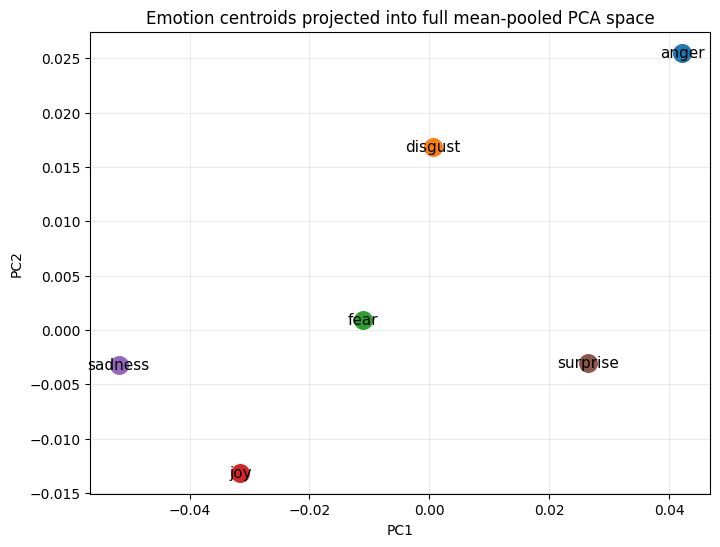


Emotion centroids in 3D PCA space (mean pooled, PCA fit on full data)
Explained variance ratio: [0.3871 0.1025 0.0842]


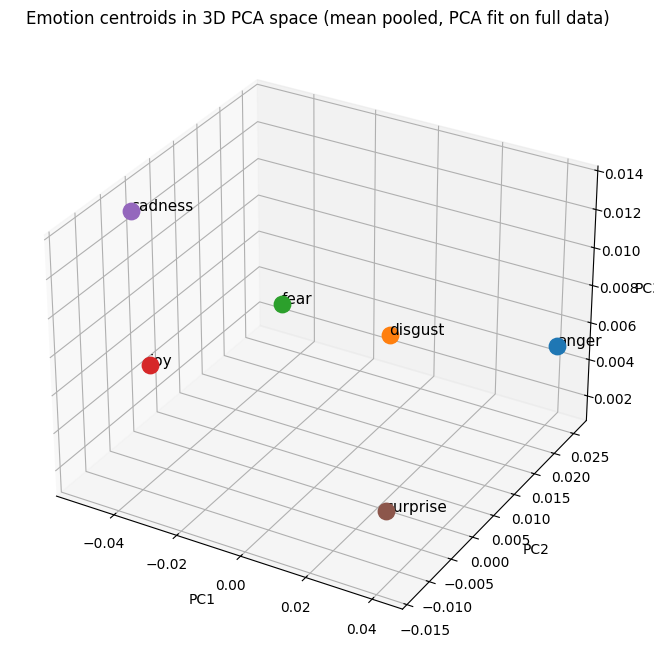


Emotion centroids projected into full CLS PCA space
Explained variance ratio: [0.441  0.1721]


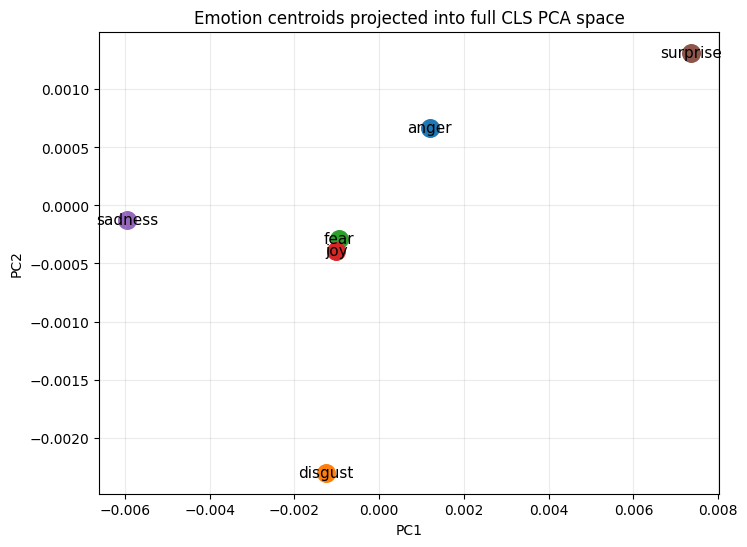

In [15]:
# mBERT visualizations

plot_centroids_in_full_pca_2d(
    mean_embeddings_norm,
    mean_centroids,
    emotion_order,
    "Emotion centroids projected into full mean-pooled PCA space"
)

plot_centroids_in_full_pca_3d(
    mean_embeddings_norm,
    mean_centroids,
    emotion_order,
    "Emotion centroids in 3D PCA space (mean pooled, PCA fit on full data)"
)

# Optional direct comparison with CLS
plot_centroids_in_full_pca_2d(
    cls_embeddings_norm,
    cls_centroids,
    emotion_order,
    "Emotion centroids projected into full CLS PCA space"
)


=== Mean-pooled probe ===
Accuracy: 0.3335
Balanced accuracy: 0.3335
Macro F1: 0.316
Weighted F1: 0.316
              precision    recall  f1-score   support

       anger      0.295     0.345     0.318      1000
     disgust      0.361     0.504     0.421      1000
        fear      0.226     0.084     0.122      1000
         joy      0.427     0.444     0.435      1000
     sadness      0.317     0.426     0.364      1000
    surprise      0.291     0.198     0.236      1000

    accuracy                          0.334      6000
   macro avg      0.320     0.333     0.316      6000
weighted avg      0.320     0.334     0.316      6000


=== CLS probe ===
Accuracy: 0.2428
Balanced accuracy: 0.2428
Macro F1: 0.2208
Weighted F1: 0.2208
              precision    recall  f1-score   support

       anger      0.245     0.203     0.222      1000
     disgust      0.262     0.294     0.277      1000
        fear      0.118     0.009     0.017      1000
         joy      0.333     0.229   

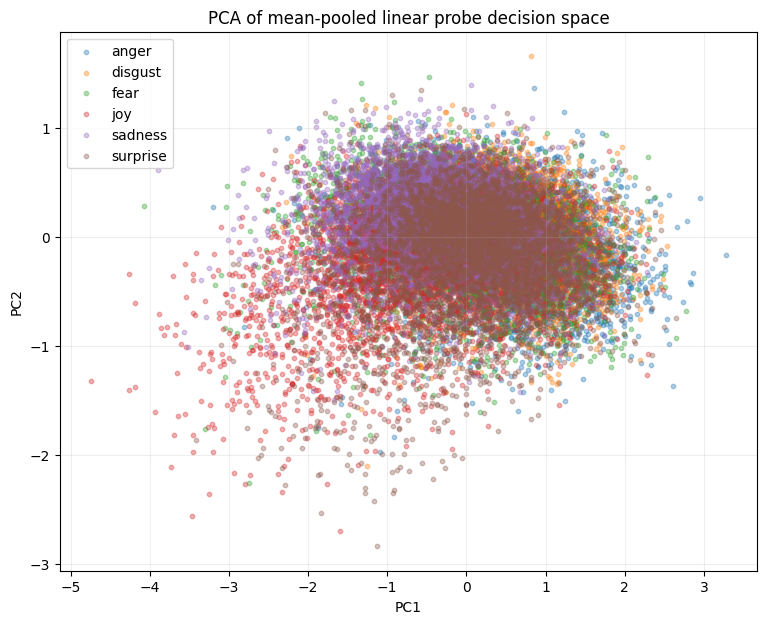


PCA of mean-pooled linear probe probability space
Probe space shape: (30000, 6)
Explained variance ratio: [0.5848 0.1939]


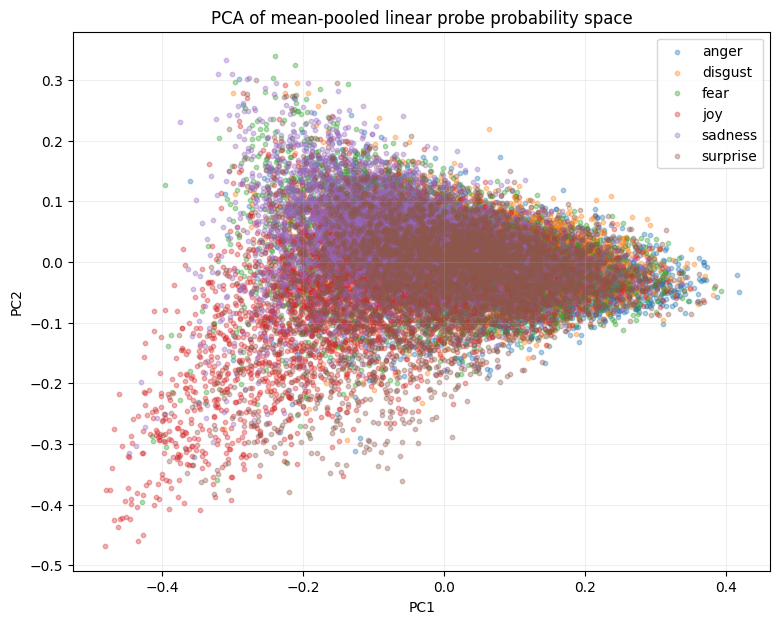


Emotion centroids in mean-pooled linear probe decision space
Probe space shape: (30000, 6)
Explained variance ratio: [0.6831 0.1665]


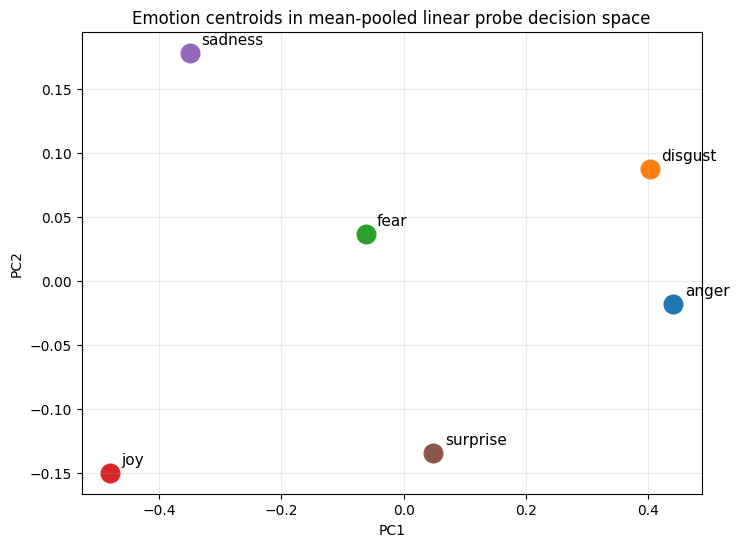


Emotion centroids in mean-pooled linear probe probability space
Probe space shape: (30000, 6)
Explained variance ratio: [0.5848 0.1939]


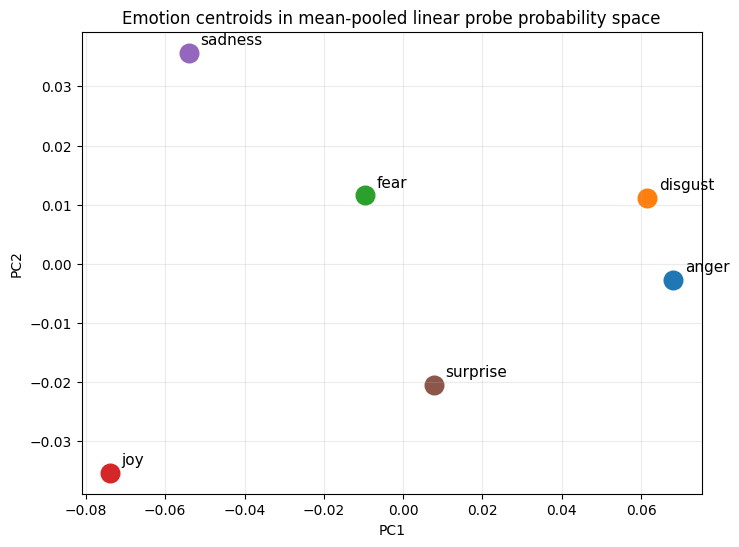


KDE contours of mean-pooled linear probe probability space
Probe space shape: (30000, 6)
Explained variance ratio: [0.5848 0.1939]


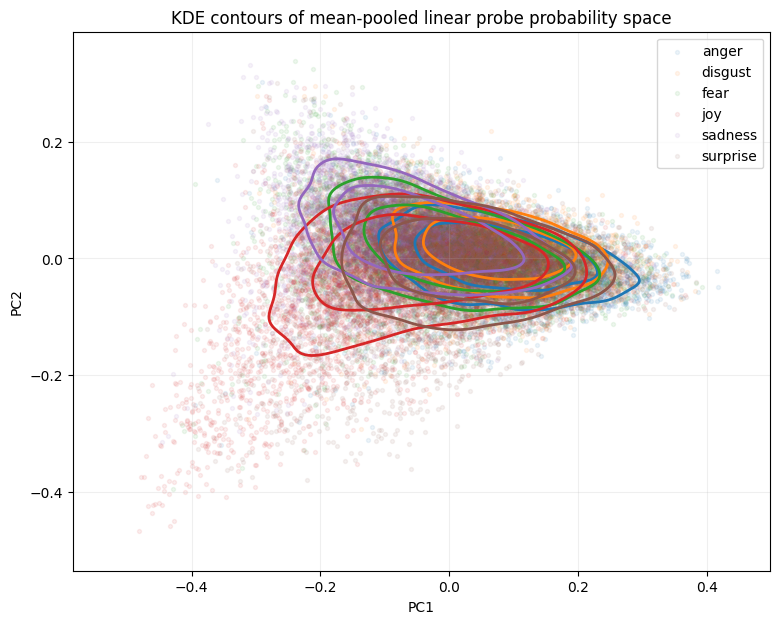


PCA of CLS linear probe decision space
Probe space shape: (30000, 6)
Explained variance ratio: [0.6984 0.2339]


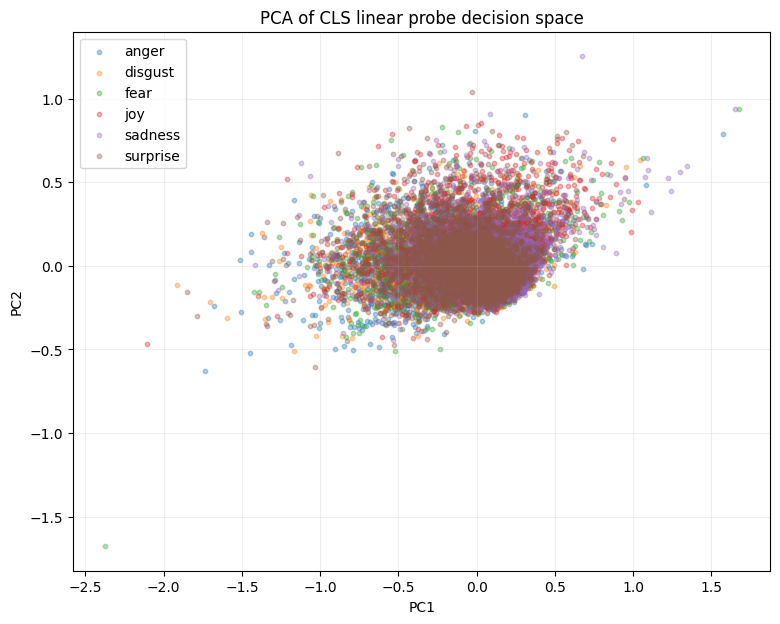


PCA of CLS linear probe probability space
Probe space shape: (30000, 6)
Explained variance ratio: [0.6788 0.2424]


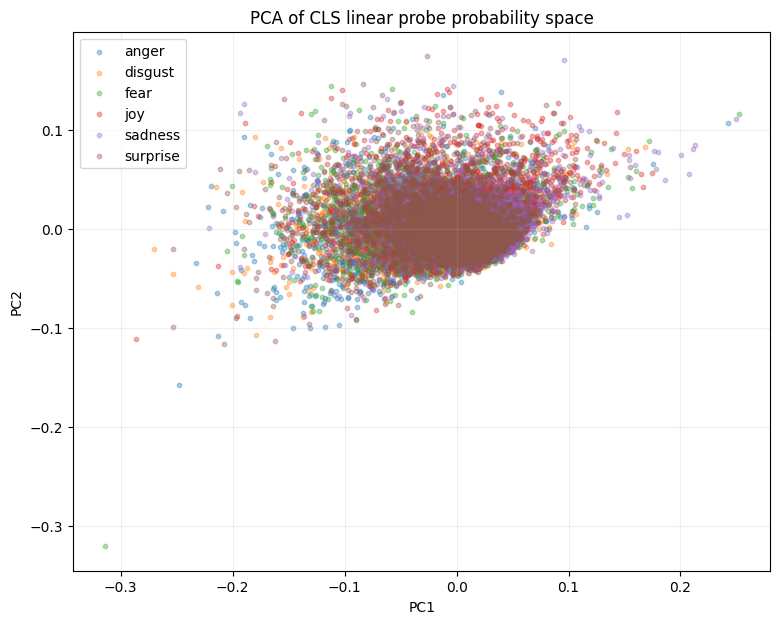


Emotion centroids in CLS linear probe decision space
Probe space shape: (30000, 6)
Explained variance ratio: [0.6984 0.2339]


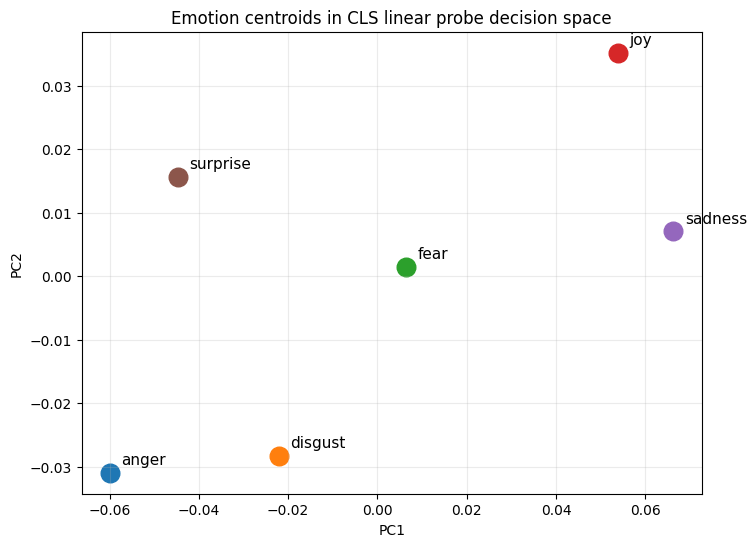


Emotion centroids in CLS linear probe probability space
Probe space shape: (30000, 6)
Explained variance ratio: [0.6788 0.2424]


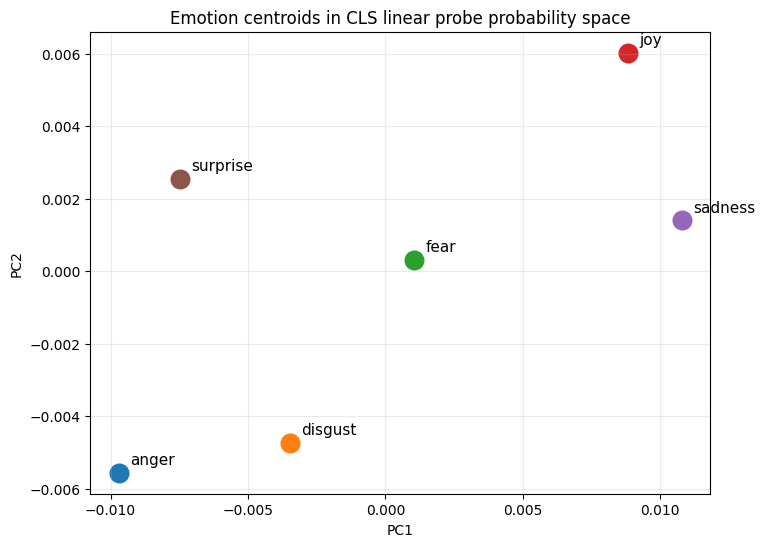


KDE contours of CLS linear probe probability space
Probe space shape: (30000, 6)
Explained variance ratio: [0.6788 0.2424]


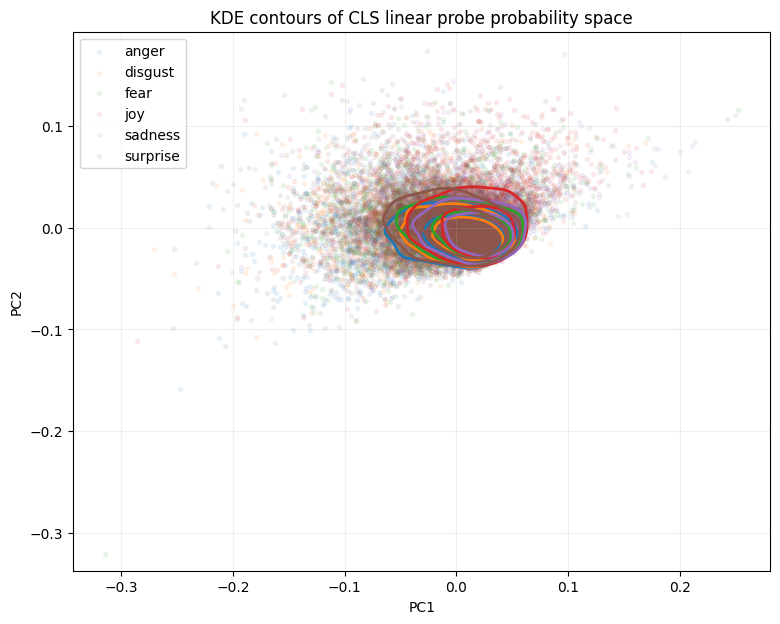

In [16]:
# probe training

mean_probe = train_probe(mean_embeddings_norm, labels, "Mean-pooled")
cls_probe = train_probe(cls_embeddings_norm, labels, "CLS")

# probe visualization

plot_probe_pca_2d(
    mean_probe,
    mean_embeddings_norm,
    labels,
    emotion_order,
    "PCA of mean-pooled linear probe decision space",
    use_probabilities=False
)

# 2. PCA of probability space (all points)
plot_probe_pca_2d(
    mean_probe,
    mean_embeddings_norm,
    labels,
    emotion_order,
    "PCA of mean-pooled linear probe probability space",
    use_probabilities=True
)

# 3. Centroids in decision space
plot_probe_centroids_pca_2d(
    mean_probe,
    mean_embeddings_norm,
    df,
    emotion_order,
    "Emotion centroids in mean-pooled linear probe decision space",
    use_probabilities=False
)

# 4. Centroids in probability space
plot_probe_centroids_pca_2d(
    mean_probe,
    mean_embeddings_norm,
    df,
    emotion_order,
    "Emotion centroids in mean-pooled linear probe probability space",
    use_probabilities=True
)

# 5. Paper-style KDE contours in probability space
plot_probe_kde_pca_2d(
    mean_probe,
    mean_embeddings_norm,
    labels,
    emotion_order,
    "KDE contours of mean-pooled linear probe probability space",
    use_probabilities=True
)

##### CLS!!!!!

# probe visualization

plot_probe_pca_2d(
    cls_probe,
    cls_embeddings_norm,
    labels,
    emotion_order,
    "PCA of CLS linear probe decision space",
    use_probabilities=False
)

# 2. PCA of probability space (all points)
plot_probe_pca_2d(
    cls_probe,
    cls_embeddings_norm,
    labels,
    emotion_order,
    "PCA of CLS linear probe probability space",
    use_probabilities=True
)

# 3. Centroids in decision space
plot_probe_centroids_pca_2d(
    cls_probe,
    cls_embeddings_norm,
    df,
    emotion_order,
    "Emotion centroids in CLS linear probe decision space",
    use_probabilities=False
)

# 4. Centroids in probability space
plot_probe_centroids_pca_2d(
    cls_probe,
    cls_embeddings_norm,
    df,
    emotion_order,
    "Emotion centroids in CLS linear probe probability space",
    use_probabilities=True
)

# 5. Paper-style KDE contours in probability space
plot_probe_kde_pca_2d(
    cls_probe,
    cls_embeddings_norm,
    labels,
    emotion_order,
    "KDE contours of CLS linear probe probability space",
    use_probabilities=True
)



Cosine similarity between mean-pooled probe weight vectors
          anger  disgust   fear    joy  sadness  surprise
anger     1.000    0.193 -0.150 -0.433   -0.363    -0.225
disgust   0.193    1.000 -0.389 -0.539   -0.413    -0.071
fear     -0.150   -0.389  1.000 -0.263    0.346    -0.102
joy      -0.433   -0.539 -0.263  1.000   -0.022     0.048
sadness  -0.363   -0.413  0.346 -0.022    1.000    -0.481
surprise -0.225   -0.071 -0.102  0.048   -0.481     1.000


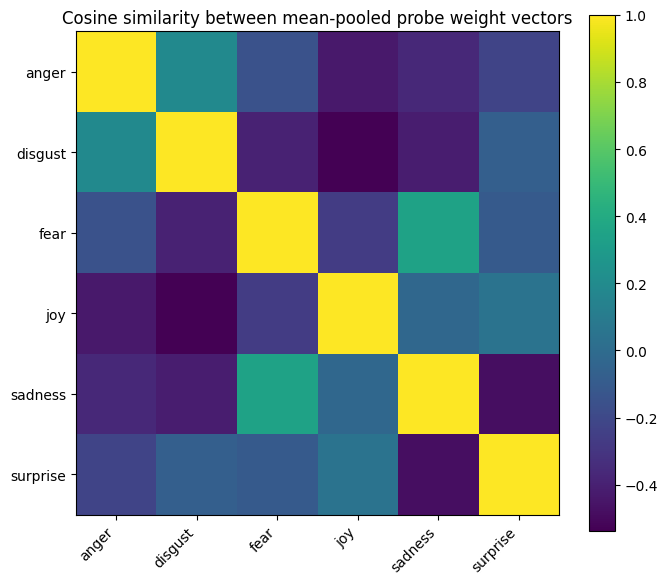


PCA of mean-pooled probe weight vectors
Weight matrix shape: (6, 768)
Explained variance ratio: [0.3504 0.2707]


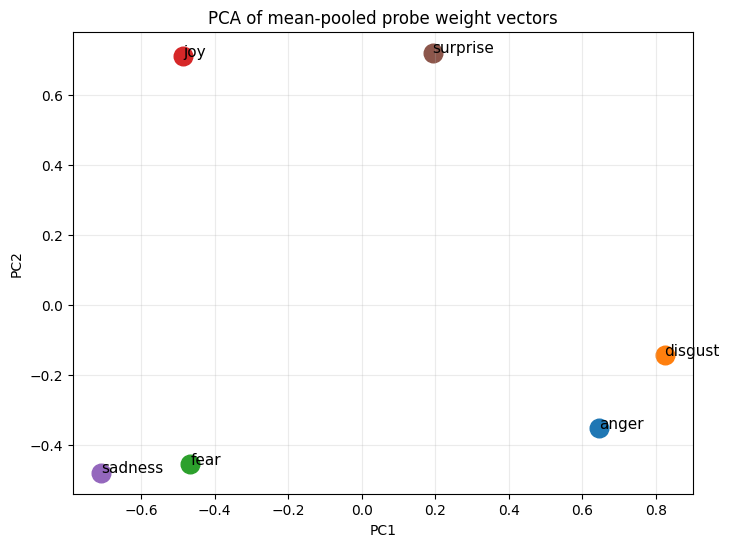


3D PCA of mean-pooled probe weight vectors
Weight matrix shape: (6, 768)
Explained variance ratio: [0.3504 0.2707 0.1719]

3D PCA coordinates (per emotion):
    PC1     PC2     PC3  emotion
 0.6448 -0.3536 -0.2392    anger
 0.8232 -0.1436 -0.1347  disgust
-0.4662 -0.4560  0.5507     fear
-0.4859  0.7119 -0.5209      joy
-0.7087 -0.4803 -0.2245  sadness
 0.1929  0.7216  0.5685 surprise

Desmos-friendly format:
anger: (0.6448, -0.3536, -0.2392)
disgust: (0.8232, -0.1436, -0.1347)
fear: (-0.4662, -0.4560, 0.5507)
joy: (-0.4859, 0.7119, -0.5209)
sadness: (-0.7087, -0.4803, -0.2245)
surprise: (0.1929, 0.7216, 0.5685)


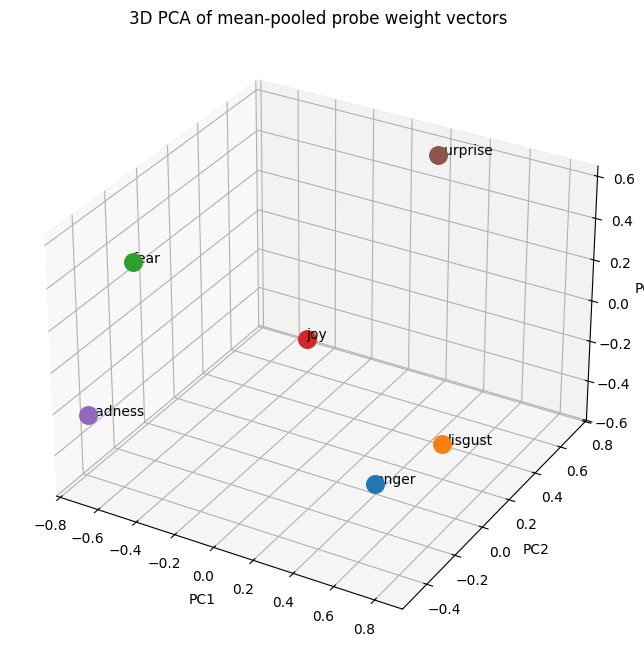


Mean-pooled probe weights vs mean-pooled class centroids
Combined shape: (12, 768)
Explained variance ratio: [0.3493 0.2231]


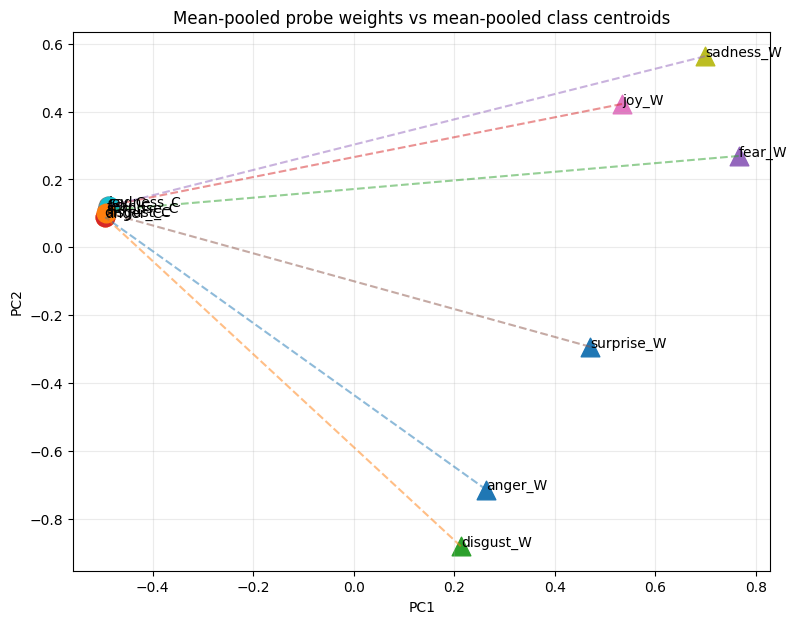


Cosine similarity between CLS probe weight vectors
          anger  disgust   fear    joy  sadness  surprise
anger     1.000    0.635 -0.267 -0.785   -0.776     0.293
disgust   0.635    1.000 -0.279 -0.722   -0.550     0.013
fear     -0.267   -0.279  1.000 -0.162    0.204     0.121
joy      -0.785   -0.722 -0.162  1.000    0.550    -0.310
sadness  -0.776   -0.550  0.204  0.550    1.000    -0.667
surprise  0.293    0.013  0.121 -0.310   -0.667     1.000


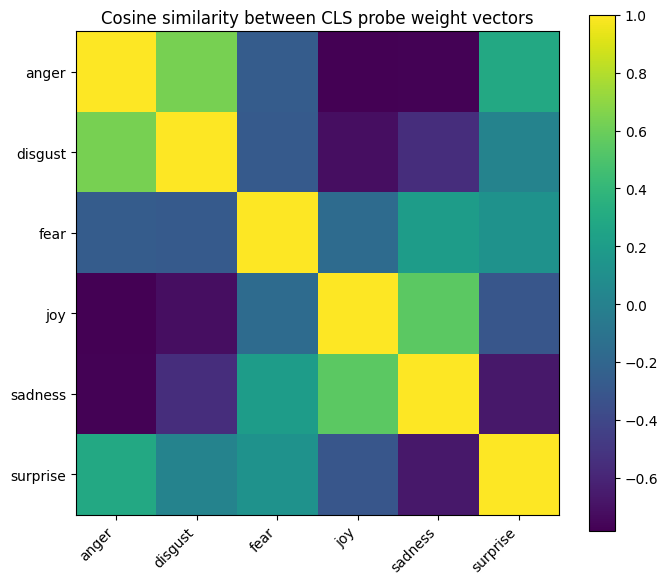


PCA of CLS probe weight vectors
Weight matrix shape: (6, 768)
Explained variance ratio: [0.546  0.2065]


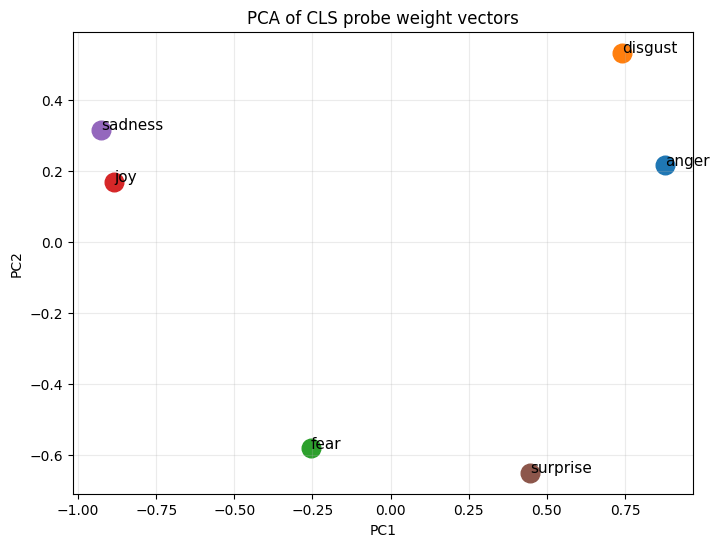


3D PCA of CLS probe weight vectors
Weight matrix shape: (6, 768)
Explained variance ratio: [0.546  0.2065 0.1652]

3D PCA coordinates (per emotion):
    PC1     PC2     PC3  emotion
 0.8768  0.2156 -0.0448    anger
 0.7410  0.5322  0.1804  disgust
-0.2547 -0.5818  0.6172     fear
-0.8839  0.1689 -0.5499      joy
-0.9262  0.3150  0.2421  sadness
 0.4470 -0.6500 -0.4451 surprise

Desmos-friendly format:
anger: (0.8768, 0.2156, -0.0448)
disgust: (0.7410, 0.5322, 0.1804)
fear: (-0.2547, -0.5818, 0.6172)
joy: (-0.8839, 0.1689, -0.5499)
sadness: (-0.9262, 0.3150, 0.2421)
surprise: (0.4470, -0.6500, -0.4451)


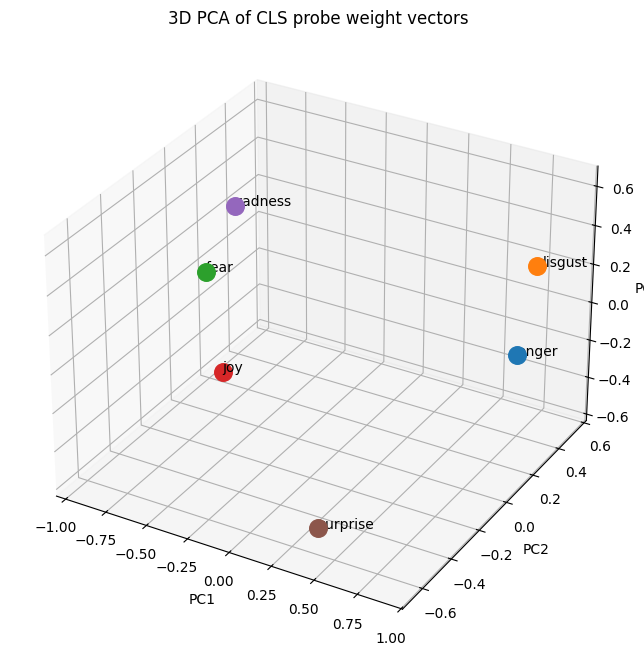


CLS probe weights vs CLS class centroids
Combined shape: (12, 768)
Explained variance ratio: [0.361  0.3453]


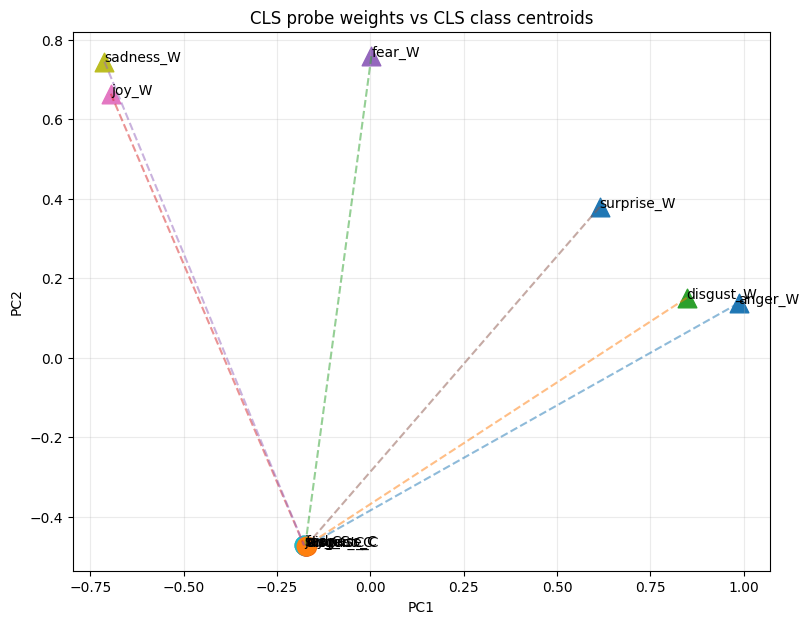

(array([[ 0.98588579,  0.13745075],
        [ 0.84704354,  0.15082763],
        [ 0.00285706,  0.75856009],
        [-0.69491955,  0.66417434],
        [-0.71179078,  0.74483423],
        [ 0.61427479,  0.37966602]]),
 array([[-0.17030821, -0.473837  ],
        [-0.17212689, -0.47332158],
        [-0.17425911, -0.4722243 ],
        [-0.17736168, -0.47172381],
        [-0.17752726, -0.47151496],
        [-0.17176771, -0.4728914 ]]),
 PCA(n_components=2, random_state=42))

In [17]:

# Probe weight analysis

class_order = list(mean_probe.classes_)

# Mean-pooled probe weights
plot_probe_weight_cosine_similarity(
    mean_probe,
    class_order,
    "Cosine similarity between mean-pooled probe weight vectors"
)

plot_probe_weights_pca_2d(
    mean_probe,
    class_order,
    "PCA of mean-pooled probe weight vectors"
)

plot_probe_weights_pca_3d(
    mean_probe,
    class_order,
    "3D PCA of mean-pooled probe weight vectors"
)

plot_probe_weights_vs_centroids_pca_2d(
    mean_probe,
    mean_centroids,
    class_order,
    "Mean-pooled probe weights vs mean-pooled class centroids"
)


# CLS probe weights
plot_probe_weight_cosine_similarity(
    cls_probe,
    class_order,
    "Cosine similarity between CLS probe weight vectors"
)

plot_probe_weights_pca_2d(
    cls_probe,
    class_order,
    "PCA of CLS probe weight vectors"
)

plot_probe_weights_pca_3d(
    cls_probe,
    class_order,
    "3D PCA of CLS probe weight vectors"
)

plot_probe_weights_vs_centroids_pca_2d(
    cls_probe,
    cls_centroids,
    class_order,
    "CLS probe weights vs CLS class centroids"
)

In [18]:
# example prediction and t-sne


print("\n--- Example predictions with mean-pooled probe ---")
predict_examples(example_texts, tokenizer, model, device, mean_probe, use_mean=True)

print("\n--- Example predictions with CLS probe ---")
predict_examples(example_texts, tokenizer, model, device, cls_probe, use_mean=False)

X_tsne_input = mean_embeddings_norm
y_tsne = df["emotion"].values


--- Example predictions with mean-pooled probe ---


Encoding: 100%|██████████| 1/1 [00:00<00:00,  1.30it/s]



TEXT: I am so happy and excited about this!
Predicted: joy
Top-3: [('joy', 0.568), ('sadness', 0.209), ('fear', 0.111)]

TEXT: This is disgusting and makes me sick.
Predicted: sadness
Top-3: [('sadness', 0.291), ('disgust', 0.238), ('joy', 0.184)]

TEXT: I am terrified something bad will happen.
Predicted: sadness
Top-3: [('sadness', 0.454), ('fear', 0.221), ('joy', 0.119)]

TEXT: I miss you so much and feel empty.
Predicted: sadness
Top-3: [('sadness', 0.42), ('joy', 0.213), ('fear', 0.155)]

TEXT: What a wonderful surprise!
Predicted: joy
Top-3: [('joy', 0.385), ('surprise', 0.246), ('fear', 0.13)]

TEXT: I am furious and cannot stand this anymore.
Predicted: sadness
Top-3: [('sadness', 0.402), ('fear', 0.208), ('joy', 0.155)]

--- Example predictions with CLS probe ---


Encoding: 100%|██████████| 1/1 [00:00<00:00, 17.09it/s]


TEXT: I am so happy and excited about this!
Predicted: joy
Top-3: [('joy', 0.203), ('surprise', 0.188), ('fear', 0.177)]

TEXT: This is disgusting and makes me sick.
Predicted: sadness
Top-3: [('sadness', 0.185), ('joy', 0.182), ('fear', 0.179)]

TEXT: I am terrified something bad will happen.
Predicted: joy
Top-3: [('joy', 0.204), ('surprise', 0.201), ('fear', 0.18)]

TEXT: I miss you so much and feel empty.
Predicted: joy
Top-3: [('joy', 0.206), ('sadness', 0.187), ('fear', 0.17)]

TEXT: What a wonderful surprise!
Predicted: surprise
Top-3: [('surprise', 0.193), ('joy', 0.178), ('fear', 0.17)]

TEXT: I am furious and cannot stand this anymore.
Predicted: joy
Top-3: [('joy', 0.235), ('sadness', 0.203), ('fear', 0.18)]


In [19]:
from datasets import load_dataset
import pandas as pd

target_emotions = ["anger", "disgust", "fear", "joy", "sadness", "surprise"]
random_state = 42

# =====================================================
# 1. LOAD BRIGHTER
# =====================================================
dfs = []

for split in ["train", "dev", "test"]:
    ds = load_dataset(
        "brighter-dataset/BRIGHTER-emotion-categories",
        "eng",
        split=split
    )
    df_part = ds.to_pandas()
    dfs.append(df_part)

brighter_df = pd.concat(dfs, ignore_index=True)
brighter_df["text"] = brighter_df["text"].astype(str)

# ensure all emotion columns exist + clean
for col in target_emotions:
    if col not in brighter_df.columns:
        brighter_df[col] = 0
    brighter_df[col] = brighter_df[col].fillna(0).astype(int)

# keep only single-label
brighter_df["n_active"] = brighter_df[target_emotions].sum(axis=1)
brighter_df = brighter_df[brighter_df["n_active"] == 1].copy()

# convert to single label
brighter_df["emotion"] = brighter_df[target_emotions].idxmax(axis=1)

brighter_df = brighter_df[["text", "emotion"]]

print("\nBRIGHTER distribution:")
print(brighter_df["emotion"].value_counts())


# # =====================================================
# # 2. LOAD GOEMOTIONS (your CSV)
# # =====================================================
# go_df = pd.read_csv("goemotions_english.csv")

# go_df["text"] = go_df["text"].astype(str)
# go_df["emotion"] = go_df["emotion"].astype(str)

# # keep only target emotions (important!)
# go_df = go_df[go_df["emotion"].isin(target_emotions)]

# print("\nGoEmotions distribution:")
# print(go_df["emotion"].value_counts())


# =====================================================
# 2.1 LOAD XED (your CSV)
# =====================================================
xed_df = pd.read_csv("xed_english.csv")

xed_df["text"] = xed_df["text"].astype(str)
xed_df["emotion"] = xed_df["emotion"].astype(str)

# keep only target emotions (important!)
xed_df = xed_df[xed_df["emotion"].isin(target_emotions)]

print("\XED distribution:")
print(xed_df["emotion"].value_counts())


# =====================================================
# 3. COMBINE
# =====================================================
comb_df = pd.concat([brighter_df, xed_df], ignore_index=True)

print("\nCombined distribution BEFORE balancing:")
print(comb_df["emotion"].value_counts())


# =====================================================
# 4. BALANCE
# =====================================================
target_n = comb_df["emotion"].value_counts().min()

balanced_parts = []

for emotion, group in comb_df.groupby("emotion"):
    balanced_parts.append(
        group.sample(n=target_n, random_state=random_state)
    )

comb_df = (
    pd.concat(balanced_parts, ignore_index=True)
    .sample(frac=1, random_state=random_state)
    .reset_index(drop=True)
)

print("\nBalanced rows:", len(comb_df))
print("\nBalanced distribution:")
print(comb_df["emotion"].value_counts())


# =====================================================
# 5. FINAL OUTPUT
# =====================================================
xed_texts = comb_df["text"].tolist()
xed_labels = comb_df["emotion"].tolist()


xed_mean_embeddings, xed_cls_embeddings = encode_texts(
    xed_texts,
    tokenizer,
    model,
    device,
    batch_size=BATCH_SIZE,
    max_length=MAX_LENGTH
)

xed_mean_embeddings_norm = normalize(xed_mean_embeddings, norm="l2")
xed_cls_embeddings_norm = normalize(xed_cls_embeddings, norm="l2")

print("\nXED mean embeddings shape:", xed_mean_embeddings_norm.shape)
print("XED CLS embeddings shape:", xed_cls_embeddings_norm.shape)

print("\nMean probe classes:", mean_probe.classes_)
print("CLS probe classes:", cls_probe.classes_)

class_order = list(mean_probe.classes_)

# Split df into calibration and test
mean_X_calib, mean_X_test, y_calib, y_test = train_test_split(
    xed_mean_embeddings_norm,
    xed_labels,
    test_size=0.5,
    random_state=42,
    stratify=xed_labels
)

cls_X_calib, cls_X_test, _, _ = train_test_split(
    xed_cls_embeddings_norm,
    xed_labels,
    test_size=0.5,
    random_state=42,
    stratify=xed_labels
)



print("\nCalibration set size:", len(y_calib))
print("Test set size:", len(y_test))


# Evaluation stats
def evaluate_probe_on_single_label(embeddings, probe, gold_labels, class_order, name="Probe"):
    preds = probe.predict(embeddings)
    probs = probe.predict_proba(embeddings)

    print(f"\n=== {name} on XED test ===")
    print("Accuracy:", round(accuracy_score(gold_labels, preds), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(gold_labels, preds), 4))
    print("Macro F1:", round(f1_score(gold_labels, preds, average="macro"), 4))
    print("Weighted F1:", round(f1_score(gold_labels, preds, average="weighted"), 4))
    print("Log loss:", round(log_loss(gold_labels, probs, labels=class_order), 4))
    
    
    # Top-3 accuracy
    
    top_k = 3

    # get indices of top-3 predictions per sample
    top_k_preds = np.argsort(probs, axis=1)[:, -top_k:]

    # map labels to indices
    label_to_idx = {label: i for i, label in enumerate(class_order)}
    gold_idx = np.array([label_to_idx[y] for y in gold_labels])

    # check if gold label is in top-k
    top_k_correct = [
        gold_idx[i] in top_k_preds[i]
        for i in range(len(gold_idx))
    ]

    top_k_acc = np.mean(top_k_correct)

    print(f"Top-{top_k} accuracy:", round(top_k_acc, 4))

    print("\nClassification report:")
    print(classification_report(gold_labels, preds, digits=3))

    cm = confusion_matrix(gold_labels, preds, labels=class_order)
    cm_df = pd.DataFrame(cm, index=class_order, columns=class_order)

    print("Confusion matrix:")
    print(cm_df.to_string())

    pred_idx = np.argmax(probs, axis=1)
    pred_conf = probs[np.arange(len(probs)), pred_idx]

    confidence_df = pd.DataFrame({
        "gold": gold_labels,
        "pred": preds,
        "confidence": pred_conf
    })

    per_class_conf = (
        confidence_df.groupby("gold")["confidence"]
        .agg(["mean", "std", "count"])
        .round(4)
        .rename_axis("emotion")
        .reset_index()
    )

    print("\nPer-class confidence stats:")
    print(per_class_conf.to_string(index=False))

    return {
        "preds": preds,
        "probs": probs,
        "confusion_matrix": cm_df,
        "confidence_stats": per_class_conf,
    }


# Baseline: uncalibrated
mean_base_results = evaluate_probe_on_single_label(
    mean_X_test,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled mBERT (uncalibrated)"
)


BRIGHTER distribution:
emotion
joy         1350
fear        1134
sadness      401
surprise     335
anger        198
Name: count, dtype: int64
\XED distribution:
emotion
anger       2391
joy         1721
fear        1529
sadness     1527
surprise    1429
disgust     1413
Name: count, dtype: int64

Combined distribution BEFORE balancing:
emotion
joy         3071
fear        2663
anger       2589
sadness     1928
surprise    1764
disgust     1413
Name: count, dtype: int64

Balanced rows: 8478

Balanced distribution:
emotion
anger       1413
surprise    1413
fear        1413
joy         1413
sadness     1413
disgust     1413
Name: count, dtype: int64


Encoding: 100%|██████████| 265/265 [01:32<00:00,  2.87it/s]


XED mean embeddings shape: (8478, 768)
XED CLS embeddings shape: (8478, 768)

Mean probe classes: ['anger' 'disgust' 'fear' 'joy' 'sadness' 'surprise']
CLS probe classes: ['anger' 'disgust' 'fear' 'joy' 'sadness' 'surprise']

Calibration set size: 4239
Test set size: 4239

=== Mean-pooled mBERT (uncalibrated) on XED test ===
Accuracy: 0.2708
Balanced accuracy: 0.2709
Macro F1: 0.2574
Weighted F1: 0.2574
Log loss: 1.7109
Top-3 accuracy: 0.6561

Classification report:
              precision    recall  f1-score   support

       anger      0.210     0.198     0.204       706
     disgust      0.286     0.241     0.261       706
        fear      0.288     0.151     0.198       707
         joy      0.527     0.137     0.218       707
     sadness      0.310     0.365     0.335       707
    surprise      0.237     0.533     0.328       706

    accuracy                          0.271      4239
   macro avg      0.309     0.271     0.257      4239
weighted avg      0.310     0.271     0.

In [20]:
# =====================================================
# HUMAN-LABEL FINE-TUNED PROBE
# =====================================================

from sklearn.linear_model import LogisticRegression

def train_eval_human_probe(X_calib, X_test, y_calib, y_test, class_order, name):
    human_probe = LogisticRegression(
        max_iter=3000,
        solver="lbfgs",
        class_weight="balanced",
        random_state=42
    )

    human_probe.fit(X_calib, y_calib)

    preds = human_probe.predict(X_test)
    probs = human_probe.predict_proba(X_test)

    print(f"\n=== {name}: probe trained on human calibration data ===")
    print("Accuracy:", round(accuracy_score(y_test, preds), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(y_test, preds), 4))
    print("Macro F1:", round(f1_score(y_test, preds, average="macro"), 4))
    print("Weighted F1:", round(f1_score(y_test, preds, average="weighted"), 4))
    print("Log loss:", round(log_loss(y_test, probs, labels=class_order), 4))

    top_k = 3
    top_k_preds = np.argsort(probs, axis=1)[:, -top_k:]
    label_to_idx = {label: i for i, label in enumerate(class_order)}
    gold_idx = np.array([label_to_idx[y] for y in y_test])
    top_k_acc = np.mean([gold_idx[i] in top_k_preds[i] for i in range(len(gold_idx))])
    print(f"Top-{top_k} accuracy:", round(top_k_acc, 4))

    print("\nClassification report:")
    print(classification_report(y_test, preds, digits=3))

    cm = confusion_matrix(y_test, preds, labels=class_order)
    cm_df = pd.DataFrame(cm, index=class_order, columns=class_order)
    print("Confusion matrix:")
    print(cm_df.to_string())

    return {
        "model": human_probe,
        "preds": preds,
        "probs": probs,
        "confusion_matrix": cm_df
    }


mean_human_probe_results = train_eval_human_probe(
    mean_X_calib,
    mean_X_test,
    y_calib,
    y_test,
    class_order,
    name="Mean-pooled"
)

cls_human_probe_results = train_eval_human_probe(
    cls_X_calib,
    cls_X_test,
    y_calib,
    y_test,
    class_order,
    name="CLS"
)


=== Mean-pooled: probe trained on human calibration data ===
Accuracy: 0.3513
Balanced accuracy: 0.3513
Macro F1: 0.3477
Weighted F1: 0.3476
Log loss: 1.6381
Top-3 accuracy: 0.7162

Classification report:
              precision    recall  f1-score   support

       anger      0.317     0.339     0.327       706
     disgust      0.349     0.439     0.389       706
        fear      0.339     0.221     0.267       707
         joy      0.389     0.436     0.411       707
     sadness      0.326     0.324     0.325       707
    surprise      0.384     0.350     0.366       706

    accuracy                          0.351      4239
   macro avg      0.351     0.351     0.348      4239
weighted avg      0.351     0.351     0.348      4239

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger       239      158    56   48       92       113
disgust     113      310    42   57       95        89
fear        115       81   156  165      114        76
joy          

In [21]:
from sklearn.linear_model import LogisticRegression

# =====================================================
# 6D EMOTION SUBSPACE CLASSIFIER
# =====================================================

def project_to_probe_subspace(X, probe, use_bias=False):
    W = probe.coef_.copy()
    Z = X @ W.T

    if use_bias:
        Z = Z + probe.intercept_

    return Z


def train_eval_6d_classifier(X_calib, X_test, y_calib, y_test, probe, class_order, name, use_bias=False):
    Z_calib = project_to_probe_subspace(X_calib, probe, use_bias=use_bias)
    Z_test = project_to_probe_subspace(X_test, probe, use_bias=use_bias)

    clf_6d = LogisticRegression(
        max_iter=3000,
        solver="lbfgs",
        class_weight="balanced",
        random_state=42
    )

    clf_6d.fit(Z_calib, y_calib)

    preds = clf_6d.predict(Z_test)
    probs = clf_6d.predict_proba(Z_test)

    print(f"\n=== {name}: Logistic Regression on 6D probe subspace ===")
    print("6D train shape:", Z_calib.shape)
    print("6D test shape:", Z_test.shape)
    print("Accuracy:", round(accuracy_score(y_test, preds), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(y_test, preds), 4))
    print("Macro F1:", round(f1_score(y_test, preds, average="macro"), 4))
    print("Weighted F1:", round(f1_score(y_test, preds, average="weighted"), 4))
    print("Log loss:", round(log_loss(y_test, probs, labels=class_order), 4))

    print("\nClassification report:")
    print(classification_report(y_test, preds, digits=3))

    cm = confusion_matrix(y_test, preds, labels=class_order)
    cm_df = pd.DataFrame(cm, index=class_order, columns=class_order)

    print("Confusion matrix:")
    print(cm_df.to_string())

    return {
        "model": clf_6d,
        "Z_calib": Z_calib,
        "Z_test": Z_test,
        "preds": preds,
        "probs": probs,
        "confusion_matrix": cm_df
    }


mean_6d_results = train_eval_6d_classifier(
    mean_X_calib,
    mean_X_test,
    y_calib,
    y_test,
    mean_probe,
    class_order,
    name="Mean-pooled"
)

cls_6d_results = train_eval_6d_classifier(
    cls_X_calib,
    cls_X_test,
    y_calib,
    y_test,
    cls_probe,
    class_order,
    name="CLS"
)


=== Mean-pooled: Logistic Regression on 6D probe subspace ===
6D train shape: (4239, 6)
6D test shape: (4239, 6)
Accuracy: 0.3293
Balanced accuracy: 0.3293
Macro F1: 0.3211
Weighted F1: 0.3211
Log loss: 1.652

Classification report:
              precision    recall  f1-score   support

       anger      0.281     0.225     0.250       706
     disgust      0.336     0.424     0.375       706
        fear      0.295     0.170     0.215       707
         joy      0.371     0.448     0.406       707
     sadness      0.334     0.396     0.362       707
    surprise      0.323     0.313     0.318       706

    accuracy                          0.329      4239
   macro avg      0.323     0.329     0.321      4239
weighted avg      0.323     0.329     0.321      4239

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger       159      162    57  105      134        89
disgust      80      299    56   70      104        97
fear         81      102   120  151     

In [22]:
mean_6d_human_probe_results = train_eval_6d_classifier(
    mean_X_calib,
    mean_X_test,
    y_calib,
    y_test,
    mean_human_probe_results["model"],
    class_order,
    name="Mean-pooled human-probe 6D"
)

cls_6d_human_probe_results = train_eval_6d_classifier(
    cls_X_calib,
    cls_X_test,
    y_calib,
    y_test,
    cls_human_probe_results["model"],
    class_order,
    name="CLS human-probe 6D"
)


=== Mean-pooled human-probe 6D: Logistic Regression on 6D probe subspace ===
6D train shape: (4239, 6)
6D test shape: (4239, 6)
Accuracy: 0.3633
Balanced accuracy: 0.3633
Macro F1: 0.3617
Weighted F1: 0.3617
Log loss: 1.5958

Classification report:
              precision    recall  f1-score   support

       anger      0.355     0.351     0.353       706
     disgust      0.357     0.407     0.380       706
        fear      0.333     0.277     0.303       707
         joy      0.406     0.438     0.422       707
     sadness      0.330     0.317     0.323       707
    surprise      0.388     0.390     0.389       706

    accuracy                          0.363      4239
   macro avg      0.362     0.363     0.362      4239
weighted avg      0.362     0.363     0.362      4239

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger       248      141    70   47       84       116
disgust     116      287    51   54       97       101
fear         98       83

In [23]:
# =====================================================
# LABEL DISAGREEMENT / ERROR INSPECTION
# =====================================================

# Recreate split with indices so we can recover the original texts
all_indices = np.arange(len(comb_df))

mean_idx_calib, mean_idx_test, _, _ = train_test_split(
    all_indices,
    xed_labels,
    test_size=0.5,
    random_state=42,
    stratify=xed_labels
)

test_texts = comb_df.iloc[mean_idx_test]["text"].tolist()
test_gold = np.array(y_test)

def inspect_strong_disagreements(X_test, probe, test_texts, gold_labels, class_order, n=30, name="Probe"):
    probs = probe.predict_proba(X_test)
    preds = probe.predict(X_test)

    pred_idx = np.argmax(probs, axis=1)
    pred_conf = probs[np.arange(len(probs)), pred_idx]

    rows = []

    for i in range(len(gold_labels)):
        if preds[i] != gold_labels[i]:
            top3_idx = np.argsort(probs[i])[::-1][:3]
            top3 = [(class_order[j], round(float(probs[i, j]), 3)) for j in top3_idx]

            rows.append({
                "text": test_texts[i],
                "gold": gold_labels[i],
                "pred": preds[i],
                "confidence": pred_conf[i],
                "top3": top3
            })

    err_df = pd.DataFrame(rows).sort_values("confidence", ascending=False)

    print(f"\n=== Strongest disagreements: {name} ===")
    print("Total errors:", len(err_df))

    for _, row in err_df.head(n).iterrows():
        print("\nTEXT:", row["text"])
        print("Gold:", row["gold"])
        print("Pred:", row["pred"])
        print("Confidence:", round(row["confidence"], 4))
        print("Top-3:", row["top3"])

    return err_df


mean_error_df = inspect_strong_disagreements(
    mean_X_test,
    mean_probe,
    test_texts,
    test_gold,
    class_order,
    n=30,
    name="Mean-pooled probe"
)

cls_error_df = inspect_strong_disagreements(
    cls_X_test,
    cls_probe,
    test_texts,
    test_gold,
    class_order,
    n=30,
    name="CLS probe"
)


=== Strongest disagreements: Mean-pooled probe ===
Total errors: 3091

TEXT: &gt; the grave stomper
Gold: surprise
Pred: anger
Confidence: 0.5631
Top-3: [('anger', 0.563), ('disgust', 0.157), ('fear', 0.118)]

TEXT: &gt; the grave stomper
Gold: surprise
Pred: anger
Confidence: 0.5631
Top-3: [('anger', 0.563), ('disgust', 0.157), ('fear', 0.118)]

TEXT: What the hell was that ? !
Gold: fear
Pred: surprise
Confidence: 0.5407
Top-3: [('surprise', 0.541), ('fear', 0.149), ('disgust', 0.14)]

TEXT: What's happening , sir ?
Gold: fear
Pred: surprise
Confidence: 0.5082
Top-3: [('surprise', 0.508), ('fear', 0.149), ('joy', 0.141)]

TEXT: Why the hell not ?
Gold: anger
Pred: surprise
Confidence: 0.4901
Top-3: [('surprise', 0.49), ('fear', 0.133), ('disgust', 0.113)]

TEXT: Turn around !
Gold: anger
Pred: surprise
Confidence: 0.485
Top-3: [('surprise', 0.485), ('joy', 0.19), ('fear', 0.155)]

TEXT: Mes dames et messieurs , good night !
Gold: joy
Pred: surprise
Confidence: 0.4847
Top-3: [('surpr

In [24]:

# Projection classifier: cosine to probe weights

mean_weight_preds, mean_weight_scores = predict_with_weight_cosine(
    mean_X_test,
    mean_probe,
    class_order
)

mean_weight_results = evaluate_simple_classifier(
    y_test,
    mean_weight_preds,
    mean_weight_scores,
    class_order,
    name="Mean-pooled XLM-R (cosine to probe weights)"
)

cls_weight_preds, cls_weight_scores = predict_with_weight_cosine(
    cls_X_test,
    cls_probe,
    class_order
)

cls_weight_results = evaluate_simple_classifier(
    y_test,
    cls_weight_preds,
    cls_weight_scores,
    class_order,
    name="CLS XLM-R (cosine to probe weights)"
)


# Prototype classifier: nearest centroid

mean_proto_preds, mean_proto_scores = predict_with_prototypes(
    mean_X_test,
    mean_centroids,
    class_order
)

mean_proto_results = evaluate_simple_classifier(
    y_test,
    mean_proto_preds,
    mean_proto_scores,
    class_order,
    name="Mean-pooled XLM-R (prototype classifier)"
)

cls_proto_preds, cls_proto_scores = predict_with_prototypes(
    cls_X_test,
    cls_centroids,
    class_order
)

cls_proto_results = evaluate_simple_classifier(
    y_test,
    cls_proto_preds,
    cls_proto_scores,
    class_order,
    name="CLS XLM-R (prototype classifier)"
)




=== Mean-pooled XLM-R (cosine to probe weights) on XED test ===
Accuracy: 0.1845
Balanced accuracy: 0.1846
Macro F1: 0.0972
Weighted F1: 0.0971
Log loss: 1.7845

Classification report:
              precision    recall  f1-score   support

       anger      0.178     0.911     0.298       706
     disgust      0.127     0.068     0.088       706
        fear      0.000     0.000     0.000       707
         joy      1.000     0.006     0.011       707
     sadness      0.750     0.004     0.008       707
    surprise      0.344     0.119     0.177       706

    accuracy                          0.184      4239
   macro avg      0.400     0.185     0.097      4239
weighted avg      0.400     0.184     0.097      4239

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger       643       33     0    0        0        30
disgust     642       48     0    0        0        16
fear        608       66     0    0        1        32
joy         553       82     0   

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p


=== Mean-pooled XLM-R (prototype classifier) on XED test ===
Accuracy: 0.2048
Balanced accuracy: 0.2048
Macro F1: 0.1736
Weighted F1: 0.1736
Log loss: 1.7907

Classification report:
              precision    recall  f1-score   support

       anger      0.190     0.449     0.267       706
     disgust      0.252     0.093     0.136       706
        fear      0.171     0.010     0.019       707
         joy      0.327     0.091     0.142       707
     sadness      0.228     0.286     0.253       707
    surprise      0.179     0.300     0.224       706

    accuracy                          0.205      4239
   macro avg      0.224     0.205     0.174      4239
weighted avg      0.224     0.205     0.174      4239

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger       317       48     5   11      109       216
disgust     365       66     8   19      100       148
fear        231       44     7   46      188       191
joy         232       25     9   64 

In [25]:
### TEST

example_texts = [
    "I just got promoted at work, I can't believe it!",
    "This is absolutely disgusting, I feel sick.",
    "I'm really scared about what might happen tomorrow.",
    "I miss you so much, everything feels empty without you.",
    "Wow, I did not expect that at all!"
]

def print_topk_linear_predictions(
    texts,
    tokenizer,
    model,
    device,
    probe,
    class_order,
    use_mean=True,
    top_k=3
):
    # Encode
    mean_embs, cls_embs = encode_texts(
        texts,
        tokenizer,
        model,
        device,
        batch_size=8,
        max_length=MAX_LENGTH
    )

    if use_mean:
        X = normalize(mean_embs, norm="l2")
    else:
        X = normalize(cls_embs, norm="l2")

    # Get linear scores
    _, scores = predict_with_linear_scores(
        X,
        probe,
        class_order,
        normalize_inputs=False
    )

    print("\n=== Top-k predictions (linear scores x·w + b) ===\n")

    for i, text in enumerate(texts):
        score_vec = scores[i]

        # sort descending
        top_indices = np.argsort(score_vec)[::-1][:top_k]

        print(f"Text: {text}")
        for rank, idx in enumerate(top_indices, 1):
            emotion = class_order[idx]
            score = score_vec[idx]
            print(f"  {rank}. {emotion:10s} | score = {score:.4f}")
        print()
        
    _, scores = predict_with_weight_cosine(
        X,
        probe,
        class_order
    )

    print("\n=== Top-k predictions (just linear scores x·w) ===\n")

    for i, text in enumerate(texts):
        score_vec = scores[i]

        # sort descending
        top_indices = np.argsort(score_vec)[::-1][:top_k]

        print(f"Text: {text}")
        for rank, idx in enumerate(top_indices, 1):
            emotion = class_order[idx]
            score = score_vec[idx]
            print(f"  {rank}. {emotion:10s} | score = {score:.4f}")
        print()
        
print_topk_linear_predictions(
    example_texts,
    tokenizer,
    model,
    device,
    mean_probe,
    class_order,
    use_mean=True
)

Encoding: 100%|██████████| 1/1 [00:00<00:00,  3.50it/s]


=== Top-k predictions (linear scores x·w + b) ===

Text: I just got promoted at work, I can't believe it!
  1. sadness    | score = 0.5369
  2. fear       | score = 0.4422
  3. surprise   | score = 0.2332

Text: This is absolutely disgusting, I feel sick.
  1. sadness    | score = 0.5436
  2. fear       | score = 0.2036
  3. joy        | score = 0.0812

Text: I'm really scared about what might happen tomorrow.
  1. sadness    | score = 1.2164
  2. fear       | score = 0.6904
  3. joy        | score = 0.5338

Text: I miss you so much, everything feels empty without you.
  1. sadness    | score = 0.9877
  2. joy        | score = 0.3669
  3. fear       | score = 0.2336

Text: Wow, I did not expect that at all!
  1. joy        | score = 1.2854
  2. surprise   | score = 0.6411
  3. sadness    | score = 0.6003


=== Top-k predictions (just linear scores x·w) ===

Text: I just got promoted at work, I can't believe it!
  1. anger      | score = 0.0490
  2. disgust    | score = 0.0246
  3. sur

In [26]:
def compute_label_centroids(X, y, class_order):
    y = np.array(y)
    centroids = []
    for emotion in class_order:
        mask = y == emotion
        centroids.append(X[mask].mean(axis=0))
    return normalize(np.vstack(centroids), norm="l2")


# Human-labeled English centroids

mean_human_centroids = compute_label_centroids(
    mean_X_calib,
    y_calib,
    class_order
)

# CHINESE

In [27]:
import pandas as pd
import numpy as np

from scipy.linalg import orthogonal_procrustes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    log_loss
)


# Load German evaluation data

comb_df = pd.concat(
    map(pd.read_csv, ["xed_chinese.csv", "xed_tw.csv", "brighter_chinese.csv"]),
    ignore_index=True
)

comb_df["text"] = comb_df["text"].astype(str)
comb_df["emotion"] = comb_df["emotion"].astype(str)

print("Original German rows:", len(comb_df))
print("\nOriginal German class distribution:")
print(comb_df["emotion"].value_counts())


# Balance German data

random_state = 42
target_n = comb_df["emotion"].value_counts().min()

balanced_parts = []
for emotion, group in comb_df.groupby("emotion"):
    balanced_parts.append(
        group.sample(n=target_n, random_state=random_state)
    )

comb_df = (
    pd.concat(balanced_parts, ignore_index=True)
    .sample(frac=1, random_state=random_state)
    .reset_index(drop=True)
)

print("\nBalanced German rows:", len(comb_df))
print("\nBalanced German class distribution:")
print(comb_df["emotion"].value_counts())

german_texts = comb_df["text"].tolist()
german_labels = comb_df["emotion"].tolist()


# Encode German data

german_mean_embeddings, german_cls_embeddings = encode_texts(
    german_texts,
    tokenizer,
    model,
    device,
    batch_size=BATCH_SIZE,
    max_length=MAX_LENGTH
)

german_mean_embeddings_norm = normalize(german_mean_embeddings, norm="l2")
german_cls_embeddings_norm = normalize(german_cls_embeddings, norm="l2")

print("\nGerman mean embeddings shape:", german_mean_embeddings_norm.shape)
print("German CLS embeddings shape:", german_cls_embeddings_norm.shape)

class_order = list(mean_probe.classes_)


# Split German into calibration / test

mean_X_calib, mean_X_test, y_calib, y_test = train_test_split(
    german_mean_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

cls_X_calib, cls_X_test, _, _ = train_test_split(
    german_cls_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

print("\nGerman calibration set size:", len(y_calib))
print("German test set size:", len(y_test))

Original German rows: 5426

Original German class distribution:
emotion
anger       2144
joy         1732
sadness      830
surprise     311
disgust      208
fear         201
Name: count, dtype: int64

Balanced German rows: 1206

Balanced German class distribution:
emotion
anger       201
disgust     201
joy         201
fear        201
sadness     201
surprise    201
Name: count, dtype: int64


Encoding: 100%|██████████| 38/38 [00:27<00:00,  1.37it/s]


German mean embeddings shape: (1206, 768)
German CLS embeddings shape: (1206, 768)

German calibration set size: 603
German test set size: 603


In [28]:

# Helpers

def softmax_np(scores):
    scores = scores - scores.max(axis=1, keepdims=True)
    exp_scores = np.exp(scores)
    return exp_scores / exp_scores.sum(axis=1, keepdims=True)


def evaluate_probe_on_single_label(embeddings, probe, gold_labels, class_order, name="Probe"):
    preds = probe.predict(embeddings)
    probs = probe.predict_proba(embeddings)

    print(f"\n=== {name} ===")
    print("Accuracy:", round(accuracy_score(gold_labels, preds), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(gold_labels, preds), 4))
    print("Macro F1:", round(f1_score(gold_labels, preds, average="macro"), 4))
    print("Weighted F1:", round(f1_score(gold_labels, preds, average="weighted"), 4))
    print("Log loss:", round(log_loss(gold_labels, probs, labels=class_order), 4))

    print("\nClassification report:")
    print(classification_report(gold_labels, preds, digits=3))

    cm = confusion_matrix(gold_labels, preds, labels=class_order)
    cm_df = pd.DataFrame(cm, index=class_order, columns=class_order)

    print("Confusion matrix:")
    print(cm_df.to_string())

    return {
        "preds": preds,
        "probs": probs,
        "confusion_matrix": cm_df
    }


from scipy.optimize import minimize
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
import numpy as np

def fit_bias_only(
    X_calib,
    y_calib,
    probe,
    class_order,
    l2_values=(0.0, 1e-4, 1e-3, 1e-2, 1e-1, 1.0),
    random_state=42,
):
    """
    Freeze probe weights W, tune L2 regularization, and learn only bias b.
    L2 is selected using an internal split of the calibration set.
    """
    W = probe.coef_.copy()
    old_b = probe.intercept_.copy()

    label_to_idx = {label: i for i, label in enumerate(class_order)}

    X_train, X_val, y_train, y_val = train_test_split(
        X_calib,
        y_calib,
        test_size=0.3,
        random_state=random_state,
        stratify=y_calib,
    )

    y_train_idx = np.array([label_to_idx[y] for y in y_train])

    def softmax_np(scores):
        scores = scores - scores.max(axis=1, keepdims=True)
        exp_scores = np.exp(scores)
        return exp_scores / exp_scores.sum(axis=1, keepdims=True)

    def fit_for_l2(l2):
        def objective(b):
            scores = X_train @ W.T + b
            probs = softmax_np(scores)

            nll = -np.mean(
                np.log(probs[np.arange(len(y_train_idx)), y_train_idx] + 1e-12)
            )

            penalty = l2 * np.sum((b - old_b) ** 2)

            return nll + penalty

        result = minimize(
            objective,
            x0=old_b,
            method="BFGS",
        )

        return result.x

    best_l2 = None
    best_f1 = -1
    best_b = None

    print("\nBias-only calibration L2 search:")

    for l2 in l2_values:
        candidate_b = fit_for_l2(l2)

        val_scores = X_val @ W.T + candidate_b
        val_pred_idx = np.argmax(val_scores, axis=1)
        val_preds = np.array([class_order[i] for i in val_pred_idx])

        val_f1 = f1_score(y_val, val_preds, average="macro")

        print(f"  l2={l2:<8} validation_macro_f1={val_f1:.4f}")

        if val_f1 > best_f1:
            best_f1 = val_f1
            best_l2 = l2
            best_b = candidate_b

    print(f"Best l2: {best_l2} | validation_macro_f1={best_f1:.4f}")

    # Refit final bias on the full calibration set using best L2
    y_calib_idx = np.array([label_to_idx[y] for y in y_calib])

    def final_objective(b):
        scores = X_calib @ W.T + b
        probs = softmax_np(scores)

        nll = -np.mean(
            np.log(probs[np.arange(len(y_calib_idx)), y_calib_idx] + 1e-12)
        )

        penalty = best_l2 * np.sum((b - old_b) ** 2)

        return nll + penalty

    final_result = minimize(
        final_objective,
        x0=old_b,
        method="BFGS",
    )

    return final_result.x


def evaluate_fixed_weights_new_bias(X_test, y_test, probe, new_b, class_order, name):
    W = probe.coef_.copy()
    scores = X_test @ W.T + new_b
    probs = softmax_np(scores)

    pred_idx = np.argmax(probs, axis=1)
    preds = np.array([class_order[i] for i in pred_idx])

    print(f"\n=== {name} ===")
    print("Accuracy:", round(accuracy_score(y_test, preds), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(y_test, preds), 4))
    print("Macro F1:", round(f1_score(y_test, preds, average="macro"), 4))
    print("Weighted F1:", round(f1_score(y_test, preds, average="weighted"), 4))
    print("Log loss:", round(log_loss(y_test, probs, labels=class_order), 4))

    print("\nClassification report:")
    print(classification_report(y_test, preds, digits=3))

    cm = confusion_matrix(y_test, preds, labels=class_order)
    cm_df = pd.DataFrame(cm, index=class_order, columns=class_order)
    print("Confusion matrix:")
    print(cm_df.to_string())

    return {
        "preds": preds,
        "probs": probs,
        "confusion_matrix": cm_df
    }


def compute_label_centroids(X, y, class_order):
    y = np.array(y)
    centroids = []
    for emotion in class_order:
        mask = y == emotion
        centroids.append(X[mask].mean(axis=0))
    return normalize(np.vstack(centroids), norm="l2")


def fit_procrustes_from_centroids(X_calib, y_calib, target_centroids, class_order):
    """
    Learns an orthogonal rotation from German calibration centroids
    to English weak-label centroids.
    """
    source_centroids = compute_label_centroids(X_calib, y_calib, class_order)

    R, scale = orthogonal_procrustes(source_centroids, target_centroids)

    print("\nProcrustes scale:", round(scale, 4))

    return R


def apply_rotation(X, R):
    return normalize(X @ R, norm="l2")

In [29]:
from sklearn.linear_model import LogisticRegression

def project_to_probe_subspace(X, probe):
    """
    Projects embeddings into the 6D English probe-weight emotion space:
        Z = X @ W.T
    """
    W = probe.coef_.copy()
    return X @ W.T


def evaluate_6d_logreg(Z_calib, Z_test, y_calib, y_test, class_order, name):
    clf_6d = LogisticRegression(
        max_iter=3000,
        solver="lbfgs",
        class_weight="balanced",
        random_state=42
    )

    clf_6d.fit(Z_calib, y_calib)

    preds = clf_6d.predict(Z_test)
    probs = clf_6d.predict_proba(Z_test)

    print(f"\n=== {name}: LogReg on 6D projected emotion space ===")
    print("6D train shape:", Z_calib.shape)
    print("6D test shape:", Z_test.shape)
    print("Accuracy:", round(accuracy_score(y_test, preds), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(y_test, preds), 4))
    print("Macro F1:", round(f1_score(y_test, preds, average="macro"), 4))
    print("Weighted F1:", round(f1_score(y_test, preds, average="weighted"), 4))
    print("Log loss:", round(log_loss(y_test, probs, labels=class_order), 4))

    print("\nClassification report:")
    print(classification_report(y_test, preds, digits=3))

    cm = confusion_matrix(y_test, preds, labels=class_order)
    cm_df = pd.DataFrame(cm, index=class_order, columns=class_order)
    print("Confusion matrix:")
    print(cm_df.to_string())

    return {
        "model": clf_6d,
        "preds": preds,
        "probs": probs,
        "confusion_matrix": cm_df
    }

In [30]:

# 1. Direct English probe on German

mean_ar_direct = evaluate_probe_on_single_label(
    mean_X_test,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe directly on German"
)

cls_ar_direct = evaluate_probe_on_single_label(
    cls_X_test,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe directly on German"
)


# 2. English probe + German bias-only calibration

mean_ar_bias = fit_bias_only(
    mean_X_calib,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_bias = fit_bias_only(
    cls_X_calib,
    y_calib,
    cls_probe,
    class_order,
    
)

print("\nOriginal mean bias:")
print(pd.Series(mean_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated mean bias:")
print(pd.Series(mean_ar_bias, index=class_order).round(4))

print("\nOriginal CLS bias:")
print(pd.Series(cls_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated CLS bias:")
print(pd.Series(cls_ar_bias, index=class_order).round(4))

mean_ar_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test,
    y_test,
    mean_probe,
    mean_ar_bias,
    class_order,
    name="Mean-pooled English weights + German learned bias"
)

cls_ar_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test,
    y_test,
    cls_probe,
    cls_ar_bias,
    class_order,
    name="CLS English weights + German learned bias"
)


# Direct German geometry-only baselines before Procrustes


mean_direct_weight_preds, mean_direct_weight_scores = predict_with_weight_cosine(
    mean_X_test,
    mean_probe,
    class_order
)

mean_direct_weight_results = evaluate_simple_classifier(
    y_test,
    mean_direct_weight_preds,
    mean_direct_weight_scores,
    class_order,
    name="Mean-pooled German direct (cosine to English probe weights)"
)

mean_direct_proto_preds, mean_direct_proto_scores = predict_with_prototypes(
    mean_X_test,
    mean_centroids,
    class_order
)

mean_direct_proto_results = evaluate_simple_classifier(
    y_test,
    mean_direct_proto_preds,
    mean_direct_proto_scores,
    class_order,
    name="Mean-pooled German direct (nearest English weak centroid)"
)

# CLS

cls_direct_weight_preds, cls_direct_weight_scores = predict_with_weight_cosine(
    cls_X_test,
    cls_probe,
    class_order
)

cls_direct_weight_results = evaluate_simple_classifier(
    y_test,
    cls_direct_weight_preds,
    cls_direct_weight_scores,
    class_order,
    name="CLS German direct (cosine to Arabic probe weights)"
)

cls_direct_proto_preds, cls_direct_proto_scores = predict_with_prototypes(
    cls_X_test,
    cls_centroids,
    class_order
)

cls_direct_proto_results = evaluate_simple_classifier(
    y_test,
    cls_direct_proto_preds,
    cls_direct_proto_scores,
    class_order,
    name="CLS German direct (nearest Arabic weak centroid)"
)


# 3. Procrustes alignment using German calibration centroids

# mean_centroids and cls_centroids should be your English weak-label training centroids
# from the earlier training dataset.
mean_R = fit_procrustes_from_centroids(
    mean_X_calib,
    y_calib,
    mean_centroids,
    class_order
)

cls_R = fit_procrustes_from_centroids(
    cls_X_calib,
    y_calib,
    cls_centroids,
    class_order
)

mean_X_calib_aligned = apply_rotation(mean_X_calib, mean_R)
mean_X_test_aligned = apply_rotation(mean_X_test, mean_R)

cls_X_calib_aligned = apply_rotation(cls_X_calib, cls_R)
cls_X_test_aligned = apply_rotation(cls_X_test, cls_R)



# 4. English probe on Procrustes-aligned German

mean_ar_proc_direct = evaluate_probe_on_single_label(
    mean_X_test_aligned,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe on Procrustes-aligned German"
)

cls_ar_proc_direct = evaluate_probe_on_single_label(
    cls_X_test_aligned,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe on Procrustes-aligned German"
    
)


# 4.5 Geometry-only baselines on Procrustes-aligned German


# Cosine to English weak probe weights
mean_proc_weight_preds, mean_proc_weight_scores = predict_with_weight_cosine(
    mean_X_test_aligned,
    mean_probe,
    class_order
)

mean_proc_weight_results = evaluate_simple_classifier(
    y_test,
    mean_proc_weight_preds,
    mean_proc_weight_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (cosine to English probe weights)"
)

cls_proc_weight_preds, cls_proc_weight_scores = predict_with_weight_cosine(
    cls_X_test_aligned,
    cls_probe,
    class_order
)

cls_proc_weight_results = evaluate_simple_classifier(
    y_test,
    cls_proc_weight_preds,
    cls_proc_weight_scores,
    class_order,
    name="CLS Procrustes-aligned German (cosine to English probe weights)"
)


# Nearest English weak-label centroid
mean_proc_proto_preds, mean_proc_proto_scores = predict_with_prototypes(
    mean_X_test_aligned,
    mean_centroids,
    class_order
)

mean_proc_proto_results = evaluate_simple_classifier(
    y_test,
    mean_proc_proto_preds,
    mean_proc_proto_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (nearest English weak centroid)"
)

cls_proc_proto_preds, cls_proc_proto_scores = predict_with_prototypes(
    cls_X_test_aligned,
    cls_centroids,
    class_order
)

cls_proc_proto_results = evaluate_simple_classifier(
    y_test,
    cls_proc_proto_preds,
    cls_proc_proto_scores,
    class_order,
    name="CLS Procrustes-aligned German (nearest English weak centroid)"
)


# 5. Procrustes alignment + German bias-only calibration

mean_ar_proc_bias = fit_bias_only(
    mean_X_calib_aligned,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_proc_bias = fit_bias_only(
    cls_X_calib_aligned,
    y_calib,
    cls_probe,
    class_order,
    
)

mean_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test_aligned,
    y_test,
    mean_probe,
    mean_ar_proc_bias,
    class_order,
    name="Mean-pooled Procrustes-aligned German + learned bias"
)

cls_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test_aligned,
    y_test,
    cls_probe,
    cls_ar_proc_bias,
    class_order,
    name="CLS Procrustes-aligned German + learned bias"
)


# 6. Procrustes alignment + 6D classifier


# Mean-pooled: German aligned embeddings -> English 6D emotion subspace
mean_Z_calib_aligned = project_to_probe_subspace(
    mean_X_calib_aligned,
    mean_probe
)

mean_Z_test_aligned = project_to_probe_subspace(
    mean_X_test_aligned,
    mean_probe
)

mean_ar_proc_6d_results = evaluate_6d_logreg(
    mean_Z_calib_aligned,
    mean_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="Mean-pooled Procrustes-aligned German"
)


# CLS: German aligned embeddings -> English 6D emotion subspace
cls_Z_calib_aligned = project_to_probe_subspace(
    cls_X_calib_aligned,
    cls_probe
)

cls_Z_test_aligned = project_to_probe_subspace(
    cls_X_test_aligned,
    cls_probe
)

cls_ar_proc_6d_results = evaluate_6d_logreg(
    cls_Z_calib_aligned,
    cls_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="CLS Procrustes-aligned German"
)


=== Mean-pooled English probe directly on German ===
Accuracy: 0.199
Balanced accuracy: 0.1999
Macro F1: 0.109
Weighted F1: 0.1087
Log loss: 1.8058

Classification report:
              precision    recall  f1-score   support

       anger      0.191     0.940     0.318       100
     disgust      0.000     0.000     0.000       100
        fear      0.143     0.010     0.019       101
         joy      0.667     0.059     0.109       101
     sadness      0.250     0.010     0.019       101
    surprise      0.200     0.180     0.189       100

    accuracy                          0.199       603
   macro avg      0.242     0.200     0.109       603
weighted avg      0.242     0.199     0.109       603

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger        94        1     0    0        0         5
disgust      82        0     2    0        1        15
fear         77        0     1    1        1        21
joy          78        0     0    6        0  

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p


Procrustes scale: 5.9926

Procrustes scale: 6.0001

=== Mean-pooled English probe on Procrustes-aligned German ===
Accuracy: 0.2653
Balanced accuracy: 0.2652
Macro F1: 0.24
Weighted F1: 0.24
Log loss: 1.846

Classification report:
              precision    recall  f1-score   support

       anger      0.289     0.260     0.274       100
     disgust      0.190     0.320     0.239       100
        fear      0.222     0.020     0.036       101
         joy      0.323     0.505     0.394       101
     sadness      0.258     0.337     0.292       101
    surprise      0.326     0.150     0.205       100

    accuracy                          0.265       603
   macro avg      0.268     0.265     0.240       603
weighted avg      0.268     0.265     0.240       603

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger        26       20     0   29       21         4
disgust      21       32     3   20       17         7
fear         11       36     2   20       

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p

              precision    recall  f1-score   support

       anger      0.208     0.870     0.336       100
     disgust      0.208     0.200     0.204       100
        fear      0.000     0.000     0.000       101
         joy      0.517     0.297     0.377       101
     sadness      0.000     0.000     0.000       101
    surprise      0.333     0.100     0.154       100

    accuracy                          0.244       603
   macro avg      0.211     0.245     0.179       603
weighted avg      0.211     0.244     0.178       603

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger        87        2     0    9        0         2
disgust      72       20     0    3        0         5
fear         61       28     0    5        0         7
joy          56        9     0   30        1         5
sadness      78       14     0    8        0         1
surprise     64       23     0    3        0        10

Per-class confidence stats:
 emotion   mean    std  c

# ESTONIAN

In [31]:
import pandas as pd
import numpy as np

from scipy.linalg import orthogonal_procrustes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    log_loss
)


# Load German evaluation data

comb_df = pd.concat(
    map(pd.read_csv, ["xed_estonian.csv"]),
    ignore_index=True
)

comb_df["text"] = comb_df["text"].astype(str)
comb_df["emotion"] = comb_df["emotion"].astype(str)

print("Original German rows:", len(comb_df))
print("\nOriginal German class distribution:")
print(comb_df["emotion"].value_counts())


# Balance German data

random_state = 42
# target_n = comb_df["emotion"].value_counts().min()
target_n = 20

balanced_parts = []
for emotion, group in comb_df.groupby("emotion"):
    balanced_parts.append(
        group.sample(n=target_n, random_state=random_state)
    )

comb_df = (
    pd.concat(balanced_parts, ignore_index=True)
    .sample(frac=1, random_state=random_state)
    .reset_index(drop=True)
)

print("\nBalanced German rows:", len(comb_df))
print("\nBalanced German class distribution:")
print(comb_df["emotion"].value_counts())

german_texts = comb_df["text"].tolist()
german_labels = comb_df["emotion"].tolist()


# Encode German data

german_mean_embeddings, german_cls_embeddings = encode_texts(
    german_texts,
    tokenizer,
    model,
    device,
    batch_size=BATCH_SIZE,
    max_length=MAX_LENGTH
)

german_mean_embeddings_norm = normalize(german_mean_embeddings, norm="l2")
german_cls_embeddings_norm = normalize(german_cls_embeddings, norm="l2")

print("\nGerman mean embeddings shape:", german_mean_embeddings_norm.shape)
print("German CLS embeddings shape:", german_cls_embeddings_norm.shape)

class_order = list(mean_probe.classes_)


# Split German into calibration / test

mean_X_calib, mean_X_test, y_calib, y_test = train_test_split(
    german_mean_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

cls_X_calib, cls_X_test, _, _ = train_test_split(
    german_cls_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

print("\nGerman calibration set size:", len(y_calib))
print("German test set size:", len(y_test))

Original German rows: 674

Original German class distribution:
emotion
anger       205
fear        106
joy         105
surprise    102
sadness     101
disgust      55
Name: count, dtype: int64

Balanced German rows: 120

Balanced German class distribution:
emotion
fear        20
anger       20
disgust     20
joy         20
surprise    20
sadness     20
Name: count, dtype: int64


Encoding: 100%|██████████| 4/4 [00:01<00:00,  3.16it/s]


German mean embeddings shape: (120, 768)
German CLS embeddings shape: (120, 768)

German calibration set size: 60
German test set size: 60


In [32]:

# 1. Direct English probe on German

mean_ar_direct = evaluate_probe_on_single_label(
    mean_X_test,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe directly on German"
)

cls_ar_direct = evaluate_probe_on_single_label(
    cls_X_test,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe directly on German"
)


# 2. English probe + German bias-only calibration

mean_ar_bias = fit_bias_only(
    mean_X_calib,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_bias = fit_bias_only(
    cls_X_calib,
    y_calib,
    cls_probe,
    class_order,
    
)

print("\nOriginal mean bias:")
print(pd.Series(mean_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated mean bias:")
print(pd.Series(mean_ar_bias, index=class_order).round(4))

print("\nOriginal CLS bias:")
print(pd.Series(cls_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated CLS bias:")
print(pd.Series(cls_ar_bias, index=class_order).round(4))

mean_ar_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test,
    y_test,
    mean_probe,
    mean_ar_bias,
    class_order,
    name="Mean-pooled English weights + German learned bias"
)

cls_ar_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test,
    y_test,
    cls_probe,
    cls_ar_bias,
    class_order,
    name="CLS English weights + German learned bias"
)


# Direct German geometry-only baselines before Procrustes


mean_direct_weight_preds, mean_direct_weight_scores = predict_with_weight_cosine(
    mean_X_test,
    mean_probe,
    class_order
)

mean_direct_weight_results = evaluate_simple_classifier(
    y_test,
    mean_direct_weight_preds,
    mean_direct_weight_scores,
    class_order,
    name="Mean-pooled German direct (cosine to English probe weights)"
)

mean_direct_proto_preds, mean_direct_proto_scores = predict_with_prototypes(
    mean_X_test,
    mean_centroids,
    class_order
)

mean_direct_proto_results = evaluate_simple_classifier(
    y_test,
    mean_direct_proto_preds,
    mean_direct_proto_scores,
    class_order,
    name="Mean-pooled German direct (nearest English weak centroid)"
)

# CLS

cls_direct_weight_preds, cls_direct_weight_scores = predict_with_weight_cosine(
    cls_X_test,
    cls_probe,
    class_order
)

cls_direct_weight_results = evaluate_simple_classifier(
    y_test,
    cls_direct_weight_preds,
    cls_direct_weight_scores,
    class_order,
    name="CLS German direct (cosine to Arabic probe weights)"
)

cls_direct_proto_preds, cls_direct_proto_scores = predict_with_prototypes(
    cls_X_test,
    cls_centroids,
    class_order
)

cls_direct_proto_results = evaluate_simple_classifier(
    y_test,
    cls_direct_proto_preds,
    cls_direct_proto_scores,
    class_order,
    name="CLS German direct (nearest Arabic weak centroid)"
)


# 3. Procrustes alignment using German calibration centroids

# mean_centroids and cls_centroids should be your English weak-label training centroids
# from the earlier training dataset.
mean_R = fit_procrustes_from_centroids(
    mean_X_calib,
    y_calib,
    mean_centroids,
    class_order
)

cls_R = fit_procrustes_from_centroids(
    cls_X_calib,
    y_calib,
    cls_centroids,
    class_order
)

mean_X_calib_aligned = apply_rotation(mean_X_calib, mean_R)
mean_X_test_aligned = apply_rotation(mean_X_test, mean_R)

cls_X_calib_aligned = apply_rotation(cls_X_calib, cls_R)
cls_X_test_aligned = apply_rotation(cls_X_test, cls_R)



# 4. English probe on Procrustes-aligned German

mean_ar_proc_direct = evaluate_probe_on_single_label(
    mean_X_test_aligned,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe on Procrustes-aligned German"
)

cls_ar_proc_direct = evaluate_probe_on_single_label(
    cls_X_test_aligned,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe on Procrustes-aligned German"
    
)


# 4.5 Geometry-only baselines on Procrustes-aligned German


# Cosine to English weak probe weights
mean_proc_weight_preds, mean_proc_weight_scores = predict_with_weight_cosine(
    mean_X_test_aligned,
    mean_probe,
    class_order
)

mean_proc_weight_results = evaluate_simple_classifier(
    y_test,
    mean_proc_weight_preds,
    mean_proc_weight_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (cosine to English probe weights)"
)

cls_proc_weight_preds, cls_proc_weight_scores = predict_with_weight_cosine(
    cls_X_test_aligned,
    cls_probe,
    class_order
)

cls_proc_weight_results = evaluate_simple_classifier(
    y_test,
    cls_proc_weight_preds,
    cls_proc_weight_scores,
    class_order,
    name="CLS Procrustes-aligned German (cosine to English probe weights)"
)


# Nearest English weak-label centroid
mean_proc_proto_preds, mean_proc_proto_scores = predict_with_prototypes(
    mean_X_test_aligned,
    mean_centroids,
    class_order
)

mean_proc_proto_results = evaluate_simple_classifier(
    y_test,
    mean_proc_proto_preds,
    mean_proc_proto_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (nearest English weak centroid)"
)

cls_proc_proto_preds, cls_proc_proto_scores = predict_with_prototypes(
    cls_X_test_aligned,
    cls_centroids,
    class_order
)

cls_proc_proto_results = evaluate_simple_classifier(
    y_test,
    cls_proc_proto_preds,
    cls_proc_proto_scores,
    class_order,
    name="CLS Procrustes-aligned German (nearest English weak centroid)"
)


# 5. Procrustes alignment + German bias-only calibration

mean_ar_proc_bias = fit_bias_only(
    mean_X_calib_aligned,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_proc_bias = fit_bias_only(
    cls_X_calib_aligned,
    y_calib,
    cls_probe,
    class_order,
    
)

mean_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test_aligned,
    y_test,
    mean_probe,
    mean_ar_proc_bias,
    class_order,
    name="Mean-pooled Procrustes-aligned German + learned bias"
)

cls_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test_aligned,
    y_test,
    cls_probe,
    cls_ar_proc_bias,
    class_order,
    name="CLS Procrustes-aligned German + learned bias"
)


# 6. Procrustes alignment + 6D classifier


# Mean-pooled: German aligned embeddings -> English 6D emotion subspace
mean_Z_calib_aligned = project_to_probe_subspace(
    mean_X_calib_aligned,
    mean_probe
)

mean_Z_test_aligned = project_to_probe_subspace(
    mean_X_test_aligned,
    mean_probe
)

mean_ar_proc_6d_results = evaluate_6d_logreg(
    mean_Z_calib_aligned,
    mean_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="Mean-pooled Procrustes-aligned German"
)


# CLS: German aligned embeddings -> English 6D emotion subspace
cls_Z_calib_aligned = project_to_probe_subspace(
    cls_X_calib_aligned,
    cls_probe
)

cls_Z_test_aligned = project_to_probe_subspace(
    cls_X_test_aligned,
    cls_probe
)

cls_ar_proc_6d_results = evaluate_6d_logreg(
    cls_Z_calib_aligned,
    cls_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="CLS Procrustes-aligned German"
)

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p


=== Mean-pooled English probe directly on German ===
Accuracy: 0.2333
Balanced accuracy: 0.2333
Macro F1: 0.1735
Weighted F1: 0.1735
Log loss: 1.8675

Classification report:
              precision    recall  f1-score   support

       anger      0.194     0.600     0.293        10
     disgust      0.333     0.500     0.400        10
        fear      0.000     0.000     0.000        10
         joy      0.000     0.000     0.000        10
     sadness      0.500     0.100     0.167        10
    surprise      0.167     0.200     0.182        10

    accuracy                          0.233        60
   macro avg      0.199     0.233     0.174        60
weighted avg      0.199     0.233     0.174        60

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger         6        0     0    0        0         4
disgust       4        5     0    0        0         1
fear          7        3     0    0        0         0
joy           1        4     0    0        1

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p


Procrustes scale: 5.997

=== Mean-pooled English probe on Procrustes-aligned German ===
Accuracy: 0.1333
Balanced accuracy: 0.1333
Macro F1: 0.1127
Weighted F1: 0.1127
Log loss: 3.3182

Classification report:
              precision    recall  f1-score   support

       anger      0.100     0.100     0.100        10
     disgust      0.267     0.400     0.320        10
        fear      0.000     0.000     0.000        10
         joy      0.069     0.200     0.103        10
     sadness      0.000     0.000     0.000        10
    surprise      0.333     0.100     0.154        10

    accuracy                          0.133        60
   macro avg      0.128     0.133     0.113        60
weighted avg      0.128     0.133     0.113        60

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger         1        1     0    7        1         0
disgust       1        4     0    4        0         1
fear          1        1     0    7        1         0
joy      

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p

  l2=0.001    validation_macro_f1=0.3762
  l2=0.01     validation_macro_f1=0.4095
  l2=0.1      validation_macro_f1=0.4095
  l2=1.0      validation_macro_f1=0.3963
Best l2: 0.01 | validation_macro_f1=0.4095

Bias-only calibration L2 search:
  l2=0.0      validation_macro_f1=0.5056
  l2=0.0001   validation_macro_f1=0.5056
  l2=0.001    validation_macro_f1=0.5056
  l2=0.01     validation_macro_f1=0.5056
  l2=0.1      validation_macro_f1=0.5056
  l2=1.0      validation_macro_f1=0.4111
Best l2: 0.0 | validation_macro_f1=0.5056

=== Mean-pooled Procrustes-aligned German + learned bias ===
Accuracy: 0.15
Balanced accuracy: 0.15
Macro F1: 0.1325
Weighted F1: 0.1325
Log loss: 3.1298

Classification report:
              precision    recall  f1-score   support

       anger      0.091     0.100     0.095        10
     disgust      0.300     0.300     0.300        10
        fear      0.000     0.000     0.000        10
         joy      0.067     0.100     0.080        10
     sadness      0.0

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p

# RUSSIAN

In [33]:
import pandas as pd
import numpy as np

from scipy.linalg import orthogonal_procrustes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    log_loss
)


# Load German evaluation data

comb_df = pd.concat(
    map(pd.read_csv, ["xed_russian.csv", "brighter_russian.csv"]),
    ignore_index=True
)

comb_df["text"] = comb_df["text"].astype(str)
comb_df["emotion"] = comb_df["emotion"].astype(str)

print("Original German rows:", len(comb_df))
print("\nOriginal German class distribution:")
print(comb_df["emotion"].value_counts())


# Balance German data

random_state = 42
target_n = comb_df["emotion"].value_counts().min()

balanced_parts = []
for emotion, group in comb_df.groupby("emotion"):
    balanced_parts.append(
        group.sample(n=target_n, random_state=random_state)
    )

comb_df = (
    pd.concat(balanced_parts, ignore_index=True)
    .sample(frac=1, random_state=random_state)
    .reset_index(drop=True)
)

print("\nBalanced German rows:", len(comb_df))
print("\nBalanced German class distribution:")
print(comb_df["emotion"].value_counts())

german_texts = comb_df["text"].tolist()
german_labels = comb_df["emotion"].tolist()


# Encode German data

german_mean_embeddings, german_cls_embeddings = encode_texts(
    german_texts,
    tokenizer,
    model,
    device,
    batch_size=BATCH_SIZE,
    max_length=MAX_LENGTH
)

german_mean_embeddings_norm = normalize(german_mean_embeddings, norm="l2")
german_cls_embeddings_norm = normalize(german_cls_embeddings, norm="l2")

print("\nGerman mean embeddings shape:", german_mean_embeddings_norm.shape)
print("German CLS embeddings shape:", german_cls_embeddings_norm.shape)

class_order = list(mean_probe.classes_)


# Split German into calibration / test

mean_X_calib, mean_X_test, y_calib, y_test = train_test_split(
    german_mean_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

cls_X_calib, cls_X_test, _, _ = train_test_split(
    german_cls_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

print("\nGerman calibration set size:", len(y_calib))
print("German test set size:", len(y_test))

Original German rows: 4540

Original German class distribution:
emotion
anger       1043
joy         1015
fear         734
sadness      724
surprise     612
disgust      412
Name: count, dtype: int64

Balanced German rows: 2472

Balanced German class distribution:
emotion
fear        412
surprise    412
sadness     412
joy         412
anger       412
disgust     412
Name: count, dtype: int64


Encoding: 100%|██████████| 78/78 [00:27<00:00,  2.86it/s]


German mean embeddings shape: (2472, 768)
German CLS embeddings shape: (2472, 768)

German calibration set size: 1236
German test set size: 1236


In [34]:

# 1. Direct English probe on German

mean_ar_direct = evaluate_probe_on_single_label(
    mean_X_test,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe directly on German"
)

cls_ar_direct = evaluate_probe_on_single_label(
    cls_X_test,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe directly on German"
)


# 2. English probe + German bias-only calibration

mean_ar_bias = fit_bias_only(
    mean_X_calib,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_bias = fit_bias_only(
    cls_X_calib,
    y_calib,
    cls_probe,
    class_order,
    
)

print("\nOriginal mean bias:")
print(pd.Series(mean_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated mean bias:")
print(pd.Series(mean_ar_bias, index=class_order).round(4))

print("\nOriginal CLS bias:")
print(pd.Series(cls_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated CLS bias:")
print(pd.Series(cls_ar_bias, index=class_order).round(4))

mean_ar_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test,
    y_test,
    mean_probe,
    mean_ar_bias,
    class_order,
    name="Mean-pooled English weights + German learned bias"
)

cls_ar_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test,
    y_test,
    cls_probe,
    cls_ar_bias,
    class_order,
    name="CLS English weights + German learned bias"
)


# Direct German geometry-only baselines before Procrustes


mean_direct_weight_preds, mean_direct_weight_scores = predict_with_weight_cosine(
    mean_X_test,
    mean_probe,
    class_order
)

mean_direct_weight_results = evaluate_simple_classifier(
    y_test,
    mean_direct_weight_preds,
    mean_direct_weight_scores,
    class_order,
    name="Mean-pooled German direct (cosine to English probe weights)"
)

mean_direct_proto_preds, mean_direct_proto_scores = predict_with_prototypes(
    mean_X_test,
    mean_centroids,
    class_order
)

mean_direct_proto_results = evaluate_simple_classifier(
    y_test,
    mean_direct_proto_preds,
    mean_direct_proto_scores,
    class_order,
    name="Mean-pooled German direct (nearest English weak centroid)"
)

# CLS

cls_direct_weight_preds, cls_direct_weight_scores = predict_with_weight_cosine(
    cls_X_test,
    cls_probe,
    class_order
)

cls_direct_weight_results = evaluate_simple_classifier(
    y_test,
    cls_direct_weight_preds,
    cls_direct_weight_scores,
    class_order,
    name="CLS German direct (cosine to Arabic probe weights)"
)

cls_direct_proto_preds, cls_direct_proto_scores = predict_with_prototypes(
    cls_X_test,
    cls_centroids,
    class_order
)

cls_direct_proto_results = evaluate_simple_classifier(
    y_test,
    cls_direct_proto_preds,
    cls_direct_proto_scores,
    class_order,
    name="CLS German direct (nearest Arabic weak centroid)"
)


# 3. Procrustes alignment using German calibration centroids

# mean_centroids and cls_centroids should be your English weak-label training centroids
# from the earlier training dataset.
mean_R = fit_procrustes_from_centroids(
    mean_X_calib,
    y_calib,
    mean_centroids,
    class_order
)

cls_R = fit_procrustes_from_centroids(
    cls_X_calib,
    y_calib,
    cls_centroids,
    class_order
)

mean_X_calib_aligned = apply_rotation(mean_X_calib, mean_R)
mean_X_test_aligned = apply_rotation(mean_X_test, mean_R)

cls_X_calib_aligned = apply_rotation(cls_X_calib, cls_R)
cls_X_test_aligned = apply_rotation(cls_X_test, cls_R)



# 4. English probe on Procrustes-aligned German

mean_ar_proc_direct = evaluate_probe_on_single_label(
    mean_X_test_aligned,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe on Procrustes-aligned German"
)

cls_ar_proc_direct = evaluate_probe_on_single_label(
    cls_X_test_aligned,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe on Procrustes-aligned German"
    
)


# 4.5 Geometry-only baselines on Procrustes-aligned German


# Cosine to English weak probe weights
mean_proc_weight_preds, mean_proc_weight_scores = predict_with_weight_cosine(
    mean_X_test_aligned,
    mean_probe,
    class_order
)

mean_proc_weight_results = evaluate_simple_classifier(
    y_test,
    mean_proc_weight_preds,
    mean_proc_weight_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (cosine to English probe weights)"
)

cls_proc_weight_preds, cls_proc_weight_scores = predict_with_weight_cosine(
    cls_X_test_aligned,
    cls_probe,
    class_order
)

cls_proc_weight_results = evaluate_simple_classifier(
    y_test,
    cls_proc_weight_preds,
    cls_proc_weight_scores,
    class_order,
    name="CLS Procrustes-aligned German (cosine to English probe weights)"
)


# Nearest English weak-label centroid
mean_proc_proto_preds, mean_proc_proto_scores = predict_with_prototypes(
    mean_X_test_aligned,
    mean_centroids,
    class_order
)

mean_proc_proto_results = evaluate_simple_classifier(
    y_test,
    mean_proc_proto_preds,
    mean_proc_proto_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (nearest English weak centroid)"
)

cls_proc_proto_preds, cls_proc_proto_scores = predict_with_prototypes(
    cls_X_test_aligned,
    cls_centroids,
    class_order
)

cls_proc_proto_results = evaluate_simple_classifier(
    y_test,
    cls_proc_proto_preds,
    cls_proc_proto_scores,
    class_order,
    name="CLS Procrustes-aligned German (nearest English weak centroid)"
)


# 5. Procrustes alignment + German bias-only calibration

mean_ar_proc_bias = fit_bias_only(
    mean_X_calib_aligned,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_proc_bias = fit_bias_only(
    cls_X_calib_aligned,
    y_calib,
    cls_probe,
    class_order,
    
)

mean_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test_aligned,
    y_test,
    mean_probe,
    mean_ar_proc_bias,
    class_order,
    name="Mean-pooled Procrustes-aligned German + learned bias"
)

cls_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test_aligned,
    y_test,
    cls_probe,
    cls_ar_proc_bias,
    class_order,
    name="CLS Procrustes-aligned German + learned bias"
)


# 6. Procrustes alignment + 6D classifier


# Mean-pooled: German aligned embeddings -> English 6D emotion subspace
mean_Z_calib_aligned = project_to_probe_subspace(
    mean_X_calib_aligned,
    mean_probe
)

mean_Z_test_aligned = project_to_probe_subspace(
    mean_X_test_aligned,
    mean_probe
)

mean_ar_proc_6d_results = evaluate_6d_logreg(
    mean_Z_calib_aligned,
    mean_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="Mean-pooled Procrustes-aligned German"
)


# CLS: German aligned embeddings -> English 6D emotion subspace
cls_Z_calib_aligned = project_to_probe_subspace(
    cls_X_calib_aligned,
    cls_probe
)

cls_Z_test_aligned = project_to_probe_subspace(
    cls_X_test_aligned,
    cls_probe
)

cls_ar_proc_6d_results = evaluate_6d_logreg(
    cls_Z_calib_aligned,
    cls_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="CLS Procrustes-aligned German"
)


=== Mean-pooled English probe directly on German ===
Accuracy: 0.267
Balanced accuracy: 0.267
Macro F1: 0.237
Weighted F1: 0.237
Log loss: 1.7632

Classification report:
              precision    recall  f1-score   support

       anger      0.221     0.529     0.312       206
     disgust      0.295     0.393     0.337       206
        fear      0.270     0.117     0.163       206
         joy      0.500     0.019     0.037       206
     sadness      0.213     0.194     0.203       206
    surprise      0.393     0.350     0.370       206

    accuracy                          0.267      1236
   macro avg      0.315     0.267     0.237      1236
weighted avg      0.315     0.267     0.237      1236

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger       109       62    12    1       12        10
disgust      64       81     9    1       35        16
fear         48       50    24    1       64        19
joy         115       15    13    4       18    

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p


=== CLS German direct (cosine to Arabic probe weights) on XED test ===
Accuracy: 0.2031
Balanced accuracy: 0.2031
Macro F1: 0.1055
Weighted F1: 0.1055
Log loss: 1.7901

Classification report:
              precision    recall  f1-score   support

       anger      0.167     0.010     0.018       206
     disgust      0.230     0.568     0.328       206
        fear      0.000     0.000     0.000       206
         joy      0.000     0.000     0.000       206
     sadness      0.000     0.000     0.000       206
    surprise      0.185     0.641     0.287       206

    accuracy                          0.203      1236
   macro avg      0.097     0.203     0.106      1236
weighted avg      0.097     0.203     0.106      1236

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger         2       93     0    0        0       111
disgust       0      117     0    0        0        89
fear          0      103     0    0        2       101
joy           6       62  

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p

              precision    recall  f1-score   support

       anger      0.167     0.039     0.063       206
     disgust      0.194     0.782     0.310       206
        fear      0.000     0.000     0.000       206
         joy      0.340     0.165     0.222       206
     sadness      0.188     0.044     0.071       206
    surprise      0.317     0.320     0.319       206

    accuracy                          0.225      1236
   macro avg      0.201     0.225     0.164      1236
weighted avg      0.201     0.225     0.164      1236

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger         8      147     0   15       10        26
disgust       6      161     0   13        8        18
fear          9      154     0    7        9        27
joy          10      114     0   34       10        38
sadness       8      140     0   16        9        33
surprise      7      116     0   15        2        66

Per-class confidence stats:
 emotion   mean    std  c

# SWAHILI

In [35]:
import pandas as pd
import numpy as np

from scipy.linalg import orthogonal_procrustes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    log_loss
)


# Load German evaluation data

comb_df = pd.concat(
    map(pd.read_csv, ["brighter_swahili.csv"]),
    ignore_index=True
)

comb_df["text"] = comb_df["text"].astype(str)
comb_df["emotion"] = comb_df["emotion"].astype(str)

print("Original German rows:", len(comb_df))
print("\nOriginal German class distribution:")
print(comb_df["emotion"].value_counts())


# Balance German data

random_state = 42
target_n = comb_df["emotion"].value_counts().min()

balanced_parts = []
for emotion, group in comb_df.groupby("emotion"):
    balanced_parts.append(
        group.sample(n=target_n, random_state=random_state)
    )

comb_df = (
    pd.concat(balanced_parts, ignore_index=True)
    .sample(frac=1, random_state=random_state)
    .reset_index(drop=True)
)

print("\nBalanced German rows:", len(comb_df))
print("\nBalanced German class distribution:")
print(comb_df["emotion"].value_counts())

german_texts = comb_df["text"].tolist()
german_labels = comb_df["emotion"].tolist()


# Encode German data

german_mean_embeddings, german_cls_embeddings = encode_texts(
    german_texts,
    tokenizer,
    model,
    device,
    batch_size=BATCH_SIZE,
    max_length=MAX_LENGTH
)

german_mean_embeddings_norm = normalize(german_mean_embeddings, norm="l2")
german_cls_embeddings_norm = normalize(german_cls_embeddings, norm="l2")

print("\nGerman mean embeddings shape:", german_mean_embeddings_norm.shape)
print("German CLS embeddings shape:", german_cls_embeddings_norm.shape)

class_order = list(mean_probe.classes_)


# Split German into calibration / test

mean_X_calib, mean_X_test, y_calib, y_test = train_test_split(
    german_mean_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

cls_X_calib, cls_X_test, _, _ = train_test_split(
    german_cls_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

print("\nGerman calibration set size:", len(y_calib))
print("German test set size:", len(y_test))

Original German rows: 3965

Original German class distribution:
emotion
surprise    1103
joy          951
sadness      675
anger        623
disgust      434
fear         179
Name: count, dtype: int64

Balanced German rows: 1074

Balanced German class distribution:
emotion
joy         179
fear        179
disgust     179
surprise    179
anger       179
sadness     179
Name: count, dtype: int64


Encoding: 100%|██████████| 34/34 [00:13<00:00,  2.47it/s]


German mean embeddings shape: (1074, 768)
German CLS embeddings shape: (1074, 768)

German calibration set size: 537
German test set size: 537


In [36]:

# 1. Direct English probe on German

mean_ar_direct = evaluate_probe_on_single_label(
    mean_X_test,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe directly on German"
)

cls_ar_direct = evaluate_probe_on_single_label(
    cls_X_test,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe directly on German"
)


# 2. English probe + German bias-only calibration

mean_ar_bias = fit_bias_only(
    mean_X_calib,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_bias = fit_bias_only(
    cls_X_calib,
    y_calib,
    cls_probe,
    class_order,
    
)

print("\nOriginal mean bias:")
print(pd.Series(mean_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated mean bias:")
print(pd.Series(mean_ar_bias, index=class_order).round(4))

print("\nOriginal CLS bias:")
print(pd.Series(cls_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated CLS bias:")
print(pd.Series(cls_ar_bias, index=class_order).round(4))

mean_ar_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test,
    y_test,
    mean_probe,
    mean_ar_bias,
    class_order,
    name="Mean-pooled English weights + German learned bias"
)

cls_ar_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test,
    y_test,
    cls_probe,
    cls_ar_bias,
    class_order,
    name="CLS English weights + German learned bias"
)


# Direct German geometry-only baselines before Procrustes


mean_direct_weight_preds, mean_direct_weight_scores = predict_with_weight_cosine(
    mean_X_test,
    mean_probe,
    class_order
)

mean_direct_weight_results = evaluate_simple_classifier(
    y_test,
    mean_direct_weight_preds,
    mean_direct_weight_scores,
    class_order,
    name="Mean-pooled German direct (cosine to English probe weights)"
)

mean_direct_proto_preds, mean_direct_proto_scores = predict_with_prototypes(
    mean_X_test,
    mean_centroids,
    class_order
)

mean_direct_proto_results = evaluate_simple_classifier(
    y_test,
    mean_direct_proto_preds,
    mean_direct_proto_scores,
    class_order,
    name="Mean-pooled German direct (nearest English weak centroid)"
)

# CLS

cls_direct_weight_preds, cls_direct_weight_scores = predict_with_weight_cosine(
    cls_X_test,
    cls_probe,
    class_order
)

cls_direct_weight_results = evaluate_simple_classifier(
    y_test,
    cls_direct_weight_preds,
    cls_direct_weight_scores,
    class_order,
    name="CLS German direct (cosine to Arabic probe weights)"
)

cls_direct_proto_preds, cls_direct_proto_scores = predict_with_prototypes(
    cls_X_test,
    cls_centroids,
    class_order
)

cls_direct_proto_results = evaluate_simple_classifier(
    y_test,
    cls_direct_proto_preds,
    cls_direct_proto_scores,
    class_order,
    name="CLS German direct (nearest Arabic weak centroid)"
)


# 3. Procrustes alignment using German calibration centroids

# mean_centroids and cls_centroids should be your English weak-label training centroids
# from the earlier training dataset.
mean_R = fit_procrustes_from_centroids(
    mean_X_calib,
    y_calib,
    mean_centroids,
    class_order
)

cls_R = fit_procrustes_from_centroids(
    cls_X_calib,
    y_calib,
    cls_centroids,
    class_order
)

mean_X_calib_aligned = apply_rotation(mean_X_calib, mean_R)
mean_X_test_aligned = apply_rotation(mean_X_test, mean_R)

cls_X_calib_aligned = apply_rotation(cls_X_calib, cls_R)
cls_X_test_aligned = apply_rotation(cls_X_test, cls_R)



# 4. English probe on Procrustes-aligned German

mean_ar_proc_direct = evaluate_probe_on_single_label(
    mean_X_test_aligned,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe on Procrustes-aligned German"
)

cls_ar_proc_direct = evaluate_probe_on_single_label(
    cls_X_test_aligned,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe on Procrustes-aligned German"
    
)


# 4.5 Geometry-only baselines on Procrustes-aligned German


# Cosine to English weak probe weights
mean_proc_weight_preds, mean_proc_weight_scores = predict_with_weight_cosine(
    mean_X_test_aligned,
    mean_probe,
    class_order
)

mean_proc_weight_results = evaluate_simple_classifier(
    y_test,
    mean_proc_weight_preds,
    mean_proc_weight_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (cosine to English probe weights)"
)

cls_proc_weight_preds, cls_proc_weight_scores = predict_with_weight_cosine(
    cls_X_test_aligned,
    cls_probe,
    class_order
)

cls_proc_weight_results = evaluate_simple_classifier(
    y_test,
    cls_proc_weight_preds,
    cls_proc_weight_scores,
    class_order,
    name="CLS Procrustes-aligned German (cosine to English probe weights)"
)


# Nearest English weak-label centroid
mean_proc_proto_preds, mean_proc_proto_scores = predict_with_prototypes(
    mean_X_test_aligned,
    mean_centroids,
    class_order
)

mean_proc_proto_results = evaluate_simple_classifier(
    y_test,
    mean_proc_proto_preds,
    mean_proc_proto_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (nearest English weak centroid)"
)

cls_proc_proto_preds, cls_proc_proto_scores = predict_with_prototypes(
    cls_X_test_aligned,
    cls_centroids,
    class_order
)

cls_proc_proto_results = evaluate_simple_classifier(
    y_test,
    cls_proc_proto_preds,
    cls_proc_proto_scores,
    class_order,
    name="CLS Procrustes-aligned German (nearest English weak centroid)"
)


# 5. Procrustes alignment + German bias-only calibration

mean_ar_proc_bias = fit_bias_only(
    mean_X_calib_aligned,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_proc_bias = fit_bias_only(
    cls_X_calib_aligned,
    y_calib,
    cls_probe,
    class_order,
    
)

mean_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test_aligned,
    y_test,
    mean_probe,
    mean_ar_proc_bias,
    class_order,
    name="Mean-pooled Procrustes-aligned German + learned bias"
)

cls_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test_aligned,
    y_test,
    cls_probe,
    cls_ar_proc_bias,
    class_order,
    name="CLS Procrustes-aligned German + learned bias"
)


# 6. Procrustes alignment + 6D classifier


# Mean-pooled: German aligned embeddings -> English 6D emotion subspace
mean_Z_calib_aligned = project_to_probe_subspace(
    mean_X_calib_aligned,
    mean_probe
)

mean_Z_test_aligned = project_to_probe_subspace(
    mean_X_test_aligned,
    mean_probe
)

mean_ar_proc_6d_results = evaluate_6d_logreg(
    mean_Z_calib_aligned,
    mean_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="Mean-pooled Procrustes-aligned German"
)


# CLS: German aligned embeddings -> English 6D emotion subspace
cls_Z_calib_aligned = project_to_probe_subspace(
    cls_X_calib_aligned,
    cls_probe
)

cls_Z_test_aligned = project_to_probe_subspace(
    cls_X_test_aligned,
    cls_probe
)

cls_ar_proc_6d_results = evaluate_6d_logreg(
    cls_Z_calib_aligned,
    cls_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="CLS Procrustes-aligned German"
)

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p


=== Mean-pooled English probe directly on German ===
Accuracy: 0.175
Balanced accuracy: 0.176
Macro F1: 0.0688
Weighted F1: 0.0684
Log loss: 2.0432

Classification report:
              precision    recall  f1-score   support

       anger      0.170     0.989     0.290        89
     disgust      0.167     0.011     0.021        89
        fear      0.000     0.000     0.000        90
         joy      1.000     0.011     0.022        90
     sadness      0.000     0.000     0.000        90
    surprise      0.333     0.045     0.079        89

    accuracy                          0.175       537
   macro avg      0.278     0.176     0.069       537
weighted avg      0.279     0.175     0.068       537

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger        88        1     0    0        0         0
disgust      88        1     0    0        0         0
fear         85        2     0    0        0         3
joy          85        0     0    1        0  

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p


Procrustes scale: 5.9964

Procrustes scale: 6.0002

=== Mean-pooled English probe on Procrustes-aligned German ===
Accuracy: 0.1955
Balanced accuracy: 0.1956
Macro F1: 0.1592
Weighted F1: 0.1593
Log loss: 2.3326

Classification report:
              precision    recall  f1-score   support

       anger      0.209     0.101     0.136        89
     disgust      0.179     0.483     0.261        89
        fear      0.167     0.033     0.056        90
         joy      0.232     0.400     0.294        90
     sadness      0.189     0.111     0.140        90
    surprise      0.143     0.045     0.068        89

    accuracy                          0.196       537
   macro avg      0.186     0.196     0.159       537
weighted avg      0.187     0.196     0.159       537

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger         9       35     5   22       12         6
disgust       6       43     2   26        8         4
fear          6       44     3   21  

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger        18       24     3   11        7        26
disgust      19       31     1   10        5        23
fear         19       28     1   11        6        25
joy          10       20     0   29       22         9
sadness      21       25     1   13       11        19
surprise     27       27     0   10        3        22

Per-class confidence stats:
 emotion   mean    std  count
   anger 0.1672 0.0004     89
 disgust 0.1672 0.0003     89
    fear 0.1672 0.0003     90
     joy 0.1676 0.0007     90
 sadness 0.1673 0.0005     90
surprise 0.1673 0.0003     89

=== CLS Procrustes-aligned German (nearest English weak centroid) on XED test ===
Accuracy: 0.2309
Balanced accuracy: 0.2309
Macro F1: 0.1718
Weighted F1: 0.1717
Log loss: 1.7917

Classification report:
              precision    recall  f1-score   support

       anger      0.364     0.090     0.144        89
     disgust      0.100     0.034     0.050  

# UKRANIAN

In [37]:
import pandas as pd
import numpy as np

from scipy.linalg import orthogonal_procrustes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    log_loss
)


# Load German evaluation data

comb_df = pd.concat(
    map(pd.read_csv, ["brighter_ukranian.csv"]),
    ignore_index=True
)

comb_df["text"] = comb_df["text"].astype(str)
comb_df["emotion"] = comb_df["emotion"].astype(str)

print("Original German rows:", len(comb_df))
print("\nOriginal German class distribution:")
print(comb_df["emotion"].value_counts())


# Balance German data

random_state = 42
target_n = comb_df["emotion"].value_counts().min()

balanced_parts = []
for emotion, group in comb_df.groupby("emotion"):
    balanced_parts.append(
        group.sample(n=target_n, random_state=random_state)
    )

comb_df = (
    pd.concat(balanced_parts, ignore_index=True)
    .sample(frac=1, random_state=random_state)
    .reset_index(drop=True)
)

print("\nBalanced German rows:", len(comb_df))
print("\nBalanced German class distribution:")
print(comb_df["emotion"].value_counts())

german_texts = comb_df["text"].tolist()
german_labels = comb_df["emotion"].tolist()


# Encode German data

german_mean_embeddings, german_cls_embeddings = encode_texts(
    german_texts,
    tokenizer,
    model,
    device,
    batch_size=BATCH_SIZE,
    max_length=MAX_LENGTH
)

german_mean_embeddings_norm = normalize(german_mean_embeddings, norm="l2")
german_cls_embeddings_norm = normalize(german_cls_embeddings, norm="l2")

print("\nGerman mean embeddings shape:", german_mean_embeddings_norm.shape)
print("German CLS embeddings shape:", german_cls_embeddings_norm.shape)

class_order = list(mean_probe.classes_)


# Split German into calibration / test

mean_X_calib, mean_X_test, y_calib, y_test = train_test_split(
    german_mean_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

cls_X_calib, cls_X_test, _, _ = train_test_split(
    german_cls_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

print("\nGerman calibration set size:", len(y_calib))
print("German test set size:", len(y_test))

Original German rows: 3583

Original German class distribution:
emotion
joy         1185
sadness      936
surprise     527
fear         479
anger        250
disgust      206
Name: count, dtype: int64

Balanced German rows: 1236

Balanced German class distribution:
emotion
disgust     206
joy         206
surprise    206
anger       206
fear        206
sadness     206
Name: count, dtype: int64


Encoding: 100%|██████████| 39/39 [00:14<00:00,  2.64it/s]


German mean embeddings shape: (1236, 768)
German CLS embeddings shape: (1236, 768)

German calibration set size: 618
German test set size: 618


In [38]:

# 1. Direct English probe on German

mean_ar_direct = evaluate_probe_on_single_label(
    mean_X_test,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe directly on German"
)

cls_ar_direct = evaluate_probe_on_single_label(
    cls_X_test,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe directly on German"
)


# 2. English probe + German bias-only calibration

mean_ar_bias = fit_bias_only(
    mean_X_calib,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_bias = fit_bias_only(
    cls_X_calib,
    y_calib,
    cls_probe,
    class_order,
    
)

print("\nOriginal mean bias:")
print(pd.Series(mean_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated mean bias:")
print(pd.Series(mean_ar_bias, index=class_order).round(4))

print("\nOriginal CLS bias:")
print(pd.Series(cls_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated CLS bias:")
print(pd.Series(cls_ar_bias, index=class_order).round(4))

mean_ar_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test,
    y_test,
    mean_probe,
    mean_ar_bias,
    class_order,
    name="Mean-pooled English weights + German learned bias"
)

cls_ar_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test,
    y_test,
    cls_probe,
    cls_ar_bias,
    class_order,
    name="CLS English weights + German learned bias"
)


# Direct German geometry-only baselines before Procrustes


mean_direct_weight_preds, mean_direct_weight_scores = predict_with_weight_cosine(
    mean_X_test,
    mean_probe,
    class_order
)

mean_direct_weight_results = evaluate_simple_classifier(
    y_test,
    mean_direct_weight_preds,
    mean_direct_weight_scores,
    class_order,
    name="Mean-pooled German direct (cosine to English probe weights)"
)

mean_direct_proto_preds, mean_direct_proto_scores = predict_with_prototypes(
    mean_X_test,
    mean_centroids,
    class_order
)

mean_direct_proto_results = evaluate_simple_classifier(
    y_test,
    mean_direct_proto_preds,
    mean_direct_proto_scores,
    class_order,
    name="Mean-pooled German direct (nearest English weak centroid)"
)

# CLS

cls_direct_weight_preds, cls_direct_weight_scores = predict_with_weight_cosine(
    cls_X_test,
    cls_probe,
    class_order
)

cls_direct_weight_results = evaluate_simple_classifier(
    y_test,
    cls_direct_weight_preds,
    cls_direct_weight_scores,
    class_order,
    name="CLS German direct (cosine to Arabic probe weights)"
)

cls_direct_proto_preds, cls_direct_proto_scores = predict_with_prototypes(
    cls_X_test,
    cls_centroids,
    class_order
)

cls_direct_proto_results = evaluate_simple_classifier(
    y_test,
    cls_direct_proto_preds,
    cls_direct_proto_scores,
    class_order,
    name="CLS German direct (nearest Arabic weak centroid)"
)


# 3. Procrustes alignment using German calibration centroids

# mean_centroids and cls_centroids should be your English weak-label training centroids
# from the earlier training dataset.
mean_R = fit_procrustes_from_centroids(
    mean_X_calib,
    y_calib,
    mean_centroids,
    class_order
)

cls_R = fit_procrustes_from_centroids(
    cls_X_calib,
    y_calib,
    cls_centroids,
    class_order
)

mean_X_calib_aligned = apply_rotation(mean_X_calib, mean_R)
mean_X_test_aligned = apply_rotation(mean_X_test, mean_R)

cls_X_calib_aligned = apply_rotation(cls_X_calib, cls_R)
cls_X_test_aligned = apply_rotation(cls_X_test, cls_R)



# 4. English probe on Procrustes-aligned German

mean_ar_proc_direct = evaluate_probe_on_single_label(
    mean_X_test_aligned,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe on Procrustes-aligned German"
)

cls_ar_proc_direct = evaluate_probe_on_single_label(
    cls_X_test_aligned,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe on Procrustes-aligned German"
    
)


# 4.5 Geometry-only baselines on Procrustes-aligned German


# Cosine to English weak probe weights
mean_proc_weight_preds, mean_proc_weight_scores = predict_with_weight_cosine(
    mean_X_test_aligned,
    mean_probe,
    class_order
)

mean_proc_weight_results = evaluate_simple_classifier(
    y_test,
    mean_proc_weight_preds,
    mean_proc_weight_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (cosine to English probe weights)"
)

cls_proc_weight_preds, cls_proc_weight_scores = predict_with_weight_cosine(
    cls_X_test_aligned,
    cls_probe,
    class_order
)

cls_proc_weight_results = evaluate_simple_classifier(
    y_test,
    cls_proc_weight_preds,
    cls_proc_weight_scores,
    class_order,
    name="CLS Procrustes-aligned German (cosine to English probe weights)"
)


# Nearest English weak-label centroid
mean_proc_proto_preds, mean_proc_proto_scores = predict_with_prototypes(
    mean_X_test_aligned,
    mean_centroids,
    class_order
)

mean_proc_proto_results = evaluate_simple_classifier(
    y_test,
    mean_proc_proto_preds,
    mean_proc_proto_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (nearest English weak centroid)"
)

cls_proc_proto_preds, cls_proc_proto_scores = predict_with_prototypes(
    cls_X_test_aligned,
    cls_centroids,
    class_order
)

cls_proc_proto_results = evaluate_simple_classifier(
    y_test,
    cls_proc_proto_preds,
    cls_proc_proto_scores,
    class_order,
    name="CLS Procrustes-aligned German (nearest English weak centroid)"
)


# 5. Procrustes alignment + German bias-only calibration

mean_ar_proc_bias = fit_bias_only(
    mean_X_calib_aligned,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_proc_bias = fit_bias_only(
    cls_X_calib_aligned,
    y_calib,
    cls_probe,
    class_order,
    
)

mean_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test_aligned,
    y_test,
    mean_probe,
    mean_ar_proc_bias,
    class_order,
    name="Mean-pooled Procrustes-aligned German + learned bias"
)

cls_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test_aligned,
    y_test,
    cls_probe,
    cls_ar_proc_bias,
    class_order,
    name="CLS Procrustes-aligned German + learned bias"
)


# 6. Procrustes alignment + 6D classifier


# Mean-pooled: German aligned embeddings -> English 6D emotion subspace
mean_Z_calib_aligned = project_to_probe_subspace(
    mean_X_calib_aligned,
    mean_probe
)

mean_Z_test_aligned = project_to_probe_subspace(
    mean_X_test_aligned,
    mean_probe
)

mean_ar_proc_6d_results = evaluate_6d_logreg(
    mean_Z_calib_aligned,
    mean_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="Mean-pooled Procrustes-aligned German"
)


# CLS: German aligned embeddings -> English 6D emotion subspace
cls_Z_calib_aligned = project_to_probe_subspace(
    cls_X_calib_aligned,
    cls_probe
)

cls_Z_test_aligned = project_to_probe_subspace(
    cls_X_test_aligned,
    cls_probe
)

cls_ar_proc_6d_results = evaluate_6d_logreg(
    cls_Z_calib_aligned,
    cls_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="CLS Procrustes-aligned German"
)

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p


=== Mean-pooled English probe directly on German ===
Accuracy: 0.2071
Balanced accuracy: 0.2071
Macro F1: 0.1618
Weighted F1: 0.1618
Log loss: 1.8155

Classification report:
              precision    recall  f1-score   support

       anger      0.190     0.641     0.293       103
     disgust      0.221     0.311     0.258       103
        fear      0.158     0.087     0.113       103
         joy      1.000     0.010     0.019       103
     sadness      0.167     0.049     0.075       103
    surprise      0.395     0.146     0.213       103

    accuracy                          0.207       618
   macro avg      0.355     0.207     0.162       618
weighted avg      0.355     0.207     0.162       618

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger        66       24     9    0        3         1
disgust      63       32     4    0        4         0
fear         54       31     9    0        2         7
joy          54       15    13    1        8

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p


Procrustes scale: 6.0

=== Mean-pooled English probe on Procrustes-aligned German ===
Accuracy: 0.2735
Balanced accuracy: 0.2735
Macro F1: 0.2656
Weighted F1: 0.2656
Log loss: 1.8517

Classification report:
              precision    recall  f1-score   support

       anger      0.220     0.252     0.235       103
     disgust      0.307     0.408     0.350       103
        fear      0.273     0.146     0.190       103
         joy      0.374     0.388     0.381       103
     sadness      0.191     0.320     0.239       103
    surprise      0.464     0.126     0.198       103

    accuracy                          0.273       618
   macro avg      0.305     0.273     0.266       618
weighted avg      0.305     0.273     0.266       618

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger        26       27     6   11       30         3
disgust      19       42     6    8       24         4
fear         15       14    15   17       37         5
joy        

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger        13       30     3    7       28        22
disgust      10       37     3   13       25        15
fear         14       35     4    8       27        15
joy          10       24     9   19       23        18
sadness       9       27     2   21       30        14
surprise     11       26     2   13       15        36

Per-class confidence stats:
 emotion   mean  std  count
   anger 0.1667  0.0    103
 disgust 0.1667  0.0    103
    fear 0.1667  0.0    103
     joy 0.1667  0.0    103
 sadness 0.1667  0.0    103
surprise 0.1667  0.0    103

Bias-only calibration L2 search:
  l2=0.0      validation_macro_f1=0.3183
  l2=0.0001   validation_macro_f1=0.3183
  l2=0.001    validation_macro_f1=0.3176
  l2=0.01     validation_macro_f1=0.3202
  l2=0.1      validation_macro_f1=0.3096
  l2=1.0      validation_macro_f1=0.3086
Best l2: 0.01 | validation_macro_f1=0.3202

Bias-only calibration L2 search:
  l2=0.0      v

# GERMAN again

In [39]:
import pandas as pd
import numpy as np

from scipy.linalg import orthogonal_procrustes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    log_loss
)


# Load German evaluation data

comb_df = pd.concat(
    map(pd.read_csv, ["xed_german.csv", "brighter_german.csv"]),
    ignore_index=True
)

comb_df["text"] = comb_df["text"].astype(str)
comb_df["emotion"] = comb_df["emotion"].astype(str)

print("Original German rows:", len(comb_df))
print("\nOriginal German class distribution:")
print(comb_df["emotion"].value_counts())


# Balance German data

random_state = 42
target_n = comb_df["emotion"].value_counts().min()

balanced_parts = []
for emotion, group in comb_df.groupby("emotion"):
    balanced_parts.append(
        group.sample(n=target_n, random_state=random_state)
    )

comb_df = (
    pd.concat(balanced_parts, ignore_index=True)
    .sample(frac=1, random_state=random_state)
    .reset_index(drop=True)
)

print("\nBalanced German rows:", len(comb_df))
print("\nBalanced German class distribution:")
print(comb_df["emotion"].value_counts())

german_texts = comb_df["text"].tolist()
german_labels = comb_df["emotion"].tolist()


# Encode German data

german_mean_embeddings, german_cls_embeddings = encode_texts(
    german_texts,
    tokenizer,
    model,
    device,
    batch_size=BATCH_SIZE,
    max_length=MAX_LENGTH
)

german_mean_embeddings_norm = normalize(german_mean_embeddings, norm="l2")
german_cls_embeddings_norm = normalize(german_cls_embeddings, norm="l2")

print("\nGerman mean embeddings shape:", german_mean_embeddings_norm.shape)
print("German CLS embeddings shape:", german_cls_embeddings_norm.shape)

class_order = list(mean_probe.classes_)


# Split German into calibration / test

mean_X_calib, mean_X_test, y_calib, y_test = train_test_split(
    german_mean_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

cls_X_calib, cls_X_test, _, _ = train_test_split(
    german_cls_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

print("\nGerman calibration set size:", len(y_calib))
print("German test set size:", len(y_test))

Original German rows: 6063

Original German class distribution:
emotion
joy         1729
anger       1218
sadness     1100
disgust      797
fear         640
surprise     579
Name: count, dtype: int64

Balanced German rows: 3474

Balanced German class distribution:
emotion
surprise    579
fear        579
disgust     579
sadness     579
anger       579
joy         579
Name: count, dtype: int64


Encoding: 100%|██████████| 109/109 [01:48<00:00,  1.01it/s]


German mean embeddings shape: (3474, 768)
German CLS embeddings shape: (3474, 768)

German calibration set size: 1737
German test set size: 1737


In [40]:

# 1. Direct English probe on German

mean_ar_direct = evaluate_probe_on_single_label(
    mean_X_test,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe directly on German"
)

cls_ar_direct = evaluate_probe_on_single_label(
    cls_X_test,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe directly on German"
)


# 2. English probe + German bias-only calibration

mean_ar_bias = fit_bias_only(
    mean_X_calib,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_bias = fit_bias_only(
    cls_X_calib,
    y_calib,
    cls_probe,
    class_order,
    
)

print("\nOriginal mean bias:")
print(pd.Series(mean_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated mean bias:")
print(pd.Series(mean_ar_bias, index=class_order).round(4))

print("\nOriginal CLS bias:")
print(pd.Series(cls_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated CLS bias:")
print(pd.Series(cls_ar_bias, index=class_order).round(4))

mean_ar_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test,
    y_test,
    mean_probe,
    mean_ar_bias,
    class_order,
    name="Mean-pooled English weights + German learned bias"
)

cls_ar_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test,
    y_test,
    cls_probe,
    cls_ar_bias,
    class_order,
    name="CLS English weights + German learned bias"
)


# Direct German geometry-only baselines before Procrustes


mean_direct_weight_preds, mean_direct_weight_scores = predict_with_weight_cosine(
    mean_X_test,
    mean_probe,
    class_order
)

mean_direct_weight_results = evaluate_simple_classifier(
    y_test,
    mean_direct_weight_preds,
    mean_direct_weight_scores,
    class_order,
    name="Mean-pooled German direct (cosine to English probe weights)"
)

mean_direct_proto_preds, mean_direct_proto_scores = predict_with_prototypes(
    mean_X_test,
    mean_centroids,
    class_order
)

mean_direct_proto_results = evaluate_simple_classifier(
    y_test,
    mean_direct_proto_preds,
    mean_direct_proto_scores,
    class_order,
    name="Mean-pooled German direct (nearest English weak centroid)"
)

# CLS

cls_direct_weight_preds, cls_direct_weight_scores = predict_with_weight_cosine(
    cls_X_test,
    cls_probe,
    class_order
)

cls_direct_weight_results = evaluate_simple_classifier(
    y_test,
    cls_direct_weight_preds,
    cls_direct_weight_scores,
    class_order,
    name="CLS German direct (cosine to Arabic probe weights)"
)

cls_direct_proto_preds, cls_direct_proto_scores = predict_with_prototypes(
    cls_X_test,
    cls_centroids,
    class_order
)

cls_direct_proto_results = evaluate_simple_classifier(
    y_test,
    cls_direct_proto_preds,
    cls_direct_proto_scores,
    class_order,
    name="CLS German direct (nearest Arabic weak centroid)"
)


# 3. Procrustes alignment using German calibration centroids

# mean_centroids and cls_centroids should be your English weak-label training centroids
# from the earlier training dataset.
mean_R = fit_procrustes_from_centroids(
    mean_X_calib,
    y_calib,
    mean_centroids,
    class_order
)

cls_R = fit_procrustes_from_centroids(
    cls_X_calib,
    y_calib,
    cls_centroids,
    class_order
)

mean_X_calib_aligned = apply_rotation(mean_X_calib, mean_R)
mean_X_test_aligned = apply_rotation(mean_X_test, mean_R)

cls_X_calib_aligned = apply_rotation(cls_X_calib, cls_R)
cls_X_test_aligned = apply_rotation(cls_X_test, cls_R)



# 4. English probe on Procrustes-aligned German

mean_ar_proc_direct = evaluate_probe_on_single_label(
    mean_X_test_aligned,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe on Procrustes-aligned German"
)

cls_ar_proc_direct = evaluate_probe_on_single_label(
    cls_X_test_aligned,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe on Procrustes-aligned German"
    
)


# 4.5 Geometry-only baselines on Procrustes-aligned German


# Cosine to English weak probe weights
mean_proc_weight_preds, mean_proc_weight_scores = predict_with_weight_cosine(
    mean_X_test_aligned,
    mean_probe,
    class_order
)

mean_proc_weight_results = evaluate_simple_classifier(
    y_test,
    mean_proc_weight_preds,
    mean_proc_weight_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (cosine to English probe weights)"
)

cls_proc_weight_preds, cls_proc_weight_scores = predict_with_weight_cosine(
    cls_X_test_aligned,
    cls_probe,
    class_order
)

cls_proc_weight_results = evaluate_simple_classifier(
    y_test,
    cls_proc_weight_preds,
    cls_proc_weight_scores,
    class_order,
    name="CLS Procrustes-aligned German (cosine to English probe weights)"
)


# Nearest English weak-label centroid
mean_proc_proto_preds, mean_proc_proto_scores = predict_with_prototypes(
    mean_X_test_aligned,
    mean_centroids,
    class_order
)

mean_proc_proto_results = evaluate_simple_classifier(
    y_test,
    mean_proc_proto_preds,
    mean_proc_proto_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (nearest English weak centroid)"
)

cls_proc_proto_preds, cls_proc_proto_scores = predict_with_prototypes(
    cls_X_test_aligned,
    cls_centroids,
    class_order
)

cls_proc_proto_results = evaluate_simple_classifier(
    y_test,
    cls_proc_proto_preds,
    cls_proc_proto_scores,
    class_order,
    name="CLS Procrustes-aligned German (nearest English weak centroid)"
)


# 5. Procrustes alignment + German bias-only calibration

mean_ar_proc_bias = fit_bias_only(
    mean_X_calib_aligned,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_proc_bias = fit_bias_only(
    cls_X_calib_aligned,
    y_calib,
    cls_probe,
    class_order,
    
)

mean_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test_aligned,
    y_test,
    mean_probe,
    mean_ar_proc_bias,
    class_order,
    name="Mean-pooled Procrustes-aligned German + learned bias"
)

cls_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test_aligned,
    y_test,
    cls_probe,
    cls_ar_proc_bias,
    class_order,
    name="CLS Procrustes-aligned German + learned bias"
)


# 6. Procrustes alignment + 6D classifier


# Mean-pooled: German aligned embeddings -> English 6D emotion subspace
mean_Z_calib_aligned = project_to_probe_subspace(
    mean_X_calib_aligned,
    mean_probe
)

mean_Z_test_aligned = project_to_probe_subspace(
    mean_X_test_aligned,
    mean_probe
)

mean_ar_proc_6d_results = evaluate_6d_logreg(
    mean_Z_calib_aligned,
    mean_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="Mean-pooled Procrustes-aligned German"
)


# CLS: German aligned embeddings -> English 6D emotion subspace
cls_Z_calib_aligned = project_to_probe_subspace(
    cls_X_calib_aligned,
    cls_probe
)

cls_Z_test_aligned = project_to_probe_subspace(
    cls_X_test_aligned,
    cls_probe
)

cls_ar_proc_6d_results = evaluate_6d_logreg(
    cls_Z_calib_aligned,
    cls_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="CLS Procrustes-aligned German"
)


=== Mean-pooled English probe directly on German ===
Accuracy: 0.2487
Balanced accuracy: 0.2489
Macro F1: 0.2287
Weighted F1: 0.2286
Log loss: 1.7574

Classification report:
              precision    recall  f1-score   support

       anger      0.227     0.325     0.267       289
     disgust      0.241     0.540     0.334       289
        fear      0.220     0.152     0.180       290
         joy      0.382     0.090     0.145       290
     sadness      0.286     0.145     0.192       290
    surprise      0.267     0.242     0.254       289

    accuracy                          0.249      1737
   macro avg      0.271     0.249     0.229      1737
weighted avg      0.271     0.249     0.229      1737

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger        94      104    18    2       26        45
disgust      71      156    27    2       10        23
fear         58      107    44    5       30        46
joy          77       90    30   26       18

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p


Per-class confidence stats:
 emotion   mean    std  count
   anger 0.1680 0.0009    289
 disgust 0.1680 0.0009    289
    fear 0.1681 0.0009    290
     joy 0.1680 0.0009    290
 sadness 0.1681 0.0009    290
surprise 0.1682 0.0011    289

=== CLS German direct (cosine to Arabic probe weights) on XED test ===
Accuracy: 0.2165
Balanced accuracy: 0.2168
Macro F1: 0.1094
Weighted F1: 0.1092
Log loss: 1.7879

Classification report:
              precision    recall  f1-score   support

       anger      0.000     0.000     0.000       289
     disgust      0.207     0.561     0.303       289
        fear      0.000     0.000     0.000       290
         joy      0.000     0.000     0.000       290
     sadness      0.500     0.003     0.007       290
    surprise      0.227     0.737     0.347       289

    accuracy                          0.216      1737
   macro avg      0.156     0.217     0.109      1737
weighted avg      0.156     0.216     0.109      1737

Confusion matrix:
       

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p

  l2=0.0      validation_macro_f1=0.2472
  l2=0.0001   validation_macro_f1=0.2472
  l2=0.001    validation_macro_f1=0.2426
  l2=0.01     validation_macro_f1=0.2450
  l2=0.1      validation_macro_f1=0.2389
  l2=1.0      validation_macro_f1=0.2390
Best l2: 0.0 | validation_macro_f1=0.2472

Bias-only calibration L2 search:
  l2=0.0      validation_macro_f1=0.2214
  l2=0.0001   validation_macro_f1=0.2214
  l2=0.001    validation_macro_f1=0.2214
  l2=0.01     validation_macro_f1=0.2182
  l2=0.1      validation_macro_f1=0.2173
  l2=1.0      validation_macro_f1=0.1996
Best l2: 0.0 | validation_macro_f1=0.2214

=== Mean-pooled Procrustes-aligned German + learned bias ===
Accuracy: 0.2631
Balanced accuracy: 0.2631
Macro F1: 0.2576
Weighted F1: 0.2576
Log loss: 1.9568

Classification report:
              precision    recall  f1-score   support

       anger      0.286     0.232     0.256       289
     disgust      0.240     0.294     0.264       289
        fear      0.231     0.155     0.186 